# IDS-LLM-Nebius v8 (IP&M revision) — Open-Source Large Language Models for Tabular Intrusion Detection: A Multi-Vendor, Multi-Seed Statistical Evaluation

Rigorous LLM evaluation for tabular intrusion detection.

## Headline empirical pattern (CIC-IDS2017 grouped, k=5, 5 seeds, v4 data preserved)

The v4 run already demonstrated the centerpiece result that v7 will validate at full scale across all 11 models and 4 datasets:

- **Aggregate accuracy**: Qwen3-235B 0.778 [0.738, 0.812] ≈ RF 0.777 [0.743, 0.812]; Mann-Whitney p = 1.00 → **statistical tie on overall accuracy**
- **Per-class F1 profile is sharply complementary**:
  - LLM ≫ RF on rare/semantic classes — Heartbleed +29 pp, BENIGN +29 pp, Brute Force +18 pp, Infiltration +10 pp
  - RF > LLM on volumetric classes — DDoS −5 pp, Port Scan −7 pp
- **Smaller LLMs (Llama-3.1-8B) are significantly worse than RF** (mean 0.616 [0.568, 0.671], p_bonf = 0.024) — establishes that the result is not "LLMs win on tabular IDS" but rather "*sufficiently large* LLMs match RF on accuracy and exceed it on rare classes."

This per-class complementarity is the conference paper's qualitative claim about Heartbleed/Infiltration, **statistically validated for the first time across multiple open-source LLMs**.

## What changed since v6

- **Model registry expanded from 6 to 11** open-source LLMs across 7 vendors. Within-family pairs (Llama 8B/70B, Hermes 70B/405B) enable scaling-laws analysis.
- **New experiment E9 — within-family scaling** with parameter-axis plots and per-class F1 deltas across model size.
- **Two new datasets** added (CSE-CIC-IDS2018, TON-IoT) — bringing total to 4, strictly larger than the published journal's 3.
- **Optional TabPFN and TabICL anchors** added via a `BASELINE_FAMILIES` switch. CPU-fallback paths included; will work on Mac M3 (CPU mode) for moderate dataset sizes; auto-detects CUDA / MPS where available.
- **All v6 instrumentation preserved** — E1-E8, R1-R2, journal-table LaTeX generator, model probe.

## Computational cost guidance

- `SCALE='quick'` (smoke test): N_TEST=8/class, no R1, ~5 min, ~\$0.50.
- `SCALE='paper'` (camera-ready): N_TEST=50/class, R1 on, **~$30-50 per dataset, per registry pass.** Full sweep of 11 models × 4 datasets × 5 seeds ≈ \$200-300. Reduce by dropping seeds, models, or datasets if budget is tighter.
- Optional TabPFN+TabICL anchors add ~10 min per dataset on Colab T4. On Mac M3 CPU: ~30 min per dataset; functional.

The notebook is **self-contained and Colab-ready** (T4 GPU sufficient). Two switches drive everything: `DATASET` (5 options) and `CLASS_GROUPING` ('fine' | 'grouped').



In [1]:
# ============================================================
# 0) INSTALL & IMPORTS
# ============================================================
!pip install -q openai==1.55.* tqdm pandas scikit-learn scipy matplotlib seaborn kagglehub tiktoken
# Optional — install only if you want TabPFN / TabICL anchors (BASELINE_FAMILIES != 'rf').
# Uncomment whichever you want. Both work on CPU; both have GPU acceleration if available.
# !pip install -q tabpfn
# !pip install -q tabicl

import os, sys, json, random, math, hashlib, time, re, uuid, gc, glob, zipfile
from dataclasses import dataclass, asdict, field
from typing import List, Dict, Any, Tuple, Optional, Iterable
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import warnings
warnings.filterwarnings("ignore")

sns.set_context("paper", font_scale=1.05)
sns.set_style("whitegrid")

print("Imports OK.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.6/389.6 kB 16.4 MB/s eta 0:00:00
Imports OK.


In [2]:
# ============================================================
# 1) NEBIUS API SETUP
# ============================================================
from openai import OpenAI

try:
    from google.colab import userdata
    NEBIUS_KEY = userdata.get("NEBIUS_API_KEY")
except Exception:
    NEBIUS_KEY = os.environ.get("NEBIUS_API_KEY", "")

assert NEBIUS_KEY, "Set NEBIUS_API_KEY in Colab Secrets (recommended) or env."

client = OpenAI(base_url="https://api.studio.nebius.com/v1/", api_key=NEBIUS_KEY)

# Model registry — display name -> Nebius model id.
# v7: expanded to 11 open-source models across 7 vendors.
# Family/size metadata enables E9 within-family scaling analysis.
#
# To drop a model, comment out its row. The model probe (cell 5b) will also
# auto-disable any model that returns errors on the smoke test.
MODEL_REGISTRY = {
    # --- Meta Llama family (within-family scaling pair: 8B vs 70B) ---
    "Llama-3.1-8B"       : "meta-llama/Meta-Llama-3.1-8B-Instruct",
    "Llama-3.3-70B"      : "meta-llama/Llama-3.3-70B-Instruct",
    # --- Alibaba Qwen ---
    "Qwen3-235B-A22B"    : "Qwen/Qwen3-235B-A22B-Instruct-2507",
    # --- DeepSeek ---
    "DeepSeek-V3"        : "deepseek-ai/DeepSeek-V3-0324",
    # --- Mistral ---
    "Mistral-Nemo-12B"   : "mistralai/Mistral-Nemo-Instruct-2407",
    # --- OpenAI gpt-oss ---
    "gpt-oss-120B"       : "openai/gpt-oss-120b",
    # --- Nous Hermes-4 family (within-family scaling pair: 70B vs 405B) ---
    "Hermes-4-70B"       : "NousResearch/Hermes-4-70B",
    "Hermes-4-405B"      : "NousResearch/Hermes-4-405B",
    # --- Google Gemma ---
    "Gemma-3-27B-it"     : "google/gemma-3-27b-it",
    # --- NVIDIA Nemotron ---
    "Nemotron-3-Super-120B" : "nvidia/nemotron-3-super-120b-a12b",
    # --- MiniMax ---
    "MiniMax-M2.5"       : "MiniMaxAI/MiniMax-M2.5",
}

# Per-model metadata for E9 scaling analysis. Sizes in billions of params
# (active params for MoE; total in parens). Family used to define within-family
# scaling pairs.
MODEL_META = {
    "Llama-3.1-8B"          : {"family": "Llama",     "size_b":   8,  "active_b":   8,  "moe": False},
    "Llama-3.3-70B"         : {"family": "Llama",     "size_b":  70,  "active_b":  70,  "moe": False},
    "Qwen3-235B-A22B"       : {"family": "Qwen3",     "size_b": 235,  "active_b":  22,  "moe": True},
    "DeepSeek-V3"           : {"family": "DeepSeek",  "size_b": 671,  "active_b":  37,  "moe": True},
    "Mistral-Nemo-12B"      : {"family": "Mistral",   "size_b":  12,  "active_b":  12,  "moe": False},
    "gpt-oss-120B"          : {"family": "gpt-oss",   "size_b": 120,  "active_b":   5.1,"moe": True},
    "Hermes-4-70B"          : {"family": "Hermes-4",  "size_b":  70,  "active_b":  70,  "moe": False},
    "Hermes-4-405B"         : {"family": "Hermes-4",  "size_b": 405,  "active_b": 405,  "moe": False},
    "Gemma-3-27B-it"        : {"family": "Gemma",     "size_b":  27,  "active_b":  27,  "moe": False},
    "Nemotron-3-Super-120B" : {"family": "Nemotron",  "size_b": 120,  "active_b":  12,  "moe": True},
    "MiniMax-M2.5"          : {"family": "MiniMax",   "size_b": 230,  "active_b":  10,  "moe": True},
}

# Within-family scaling pairs for E9. Each pair is (smaller, larger) within a
# fixed pre-training recipe. Ratio of larger/smaller indicates the scaling step.
SCALING_PAIRS = [
    ("Llama-3.1-8B",  "Llama-3.3-70B"),    # 8.75x active params, same family
    ("Hermes-4-70B",  "Hermes-4-405B"),    # 5.79x active params, same family
]

PRIMARY_MODEL = "Qwen3-235B-A22B"   # v3-v6 winner across runs

print("Nebius client ready.")
print(f"Models registered: {len(MODEL_REGISTRY)} across {len(set(m['family'] for m in MODEL_META.values()))} families")
for k, v in MODEL_REGISTRY.items():
    marker = "  *" if k == PRIMARY_MODEL else "   "
    fam = MODEL_META.get(k, {}).get("family", "?")
    sz  = MODEL_META.get(k, {}).get("active_b", "?")
    print(f"{marker} {k:<24} family={fam:<10} active={sz:>5}B  -> {v}")
print(f"\nWithin-family scaling pairs (for E9):")
for s, l in SCALING_PAIRS:
    rs = MODEL_META[s]["active_b"]; rl = MODEL_META[l]["active_b"]
    print(f"  {s:<22} -> {l:<22}  ({rl/rs:.1f}x active params)")


Nebius client ready.
Models registered: 11 across 9 families
    Llama-3.1-8B             family=Llama      active=    8B  -> meta-llama/Meta-Llama-3.1-8B-Instruct
    Llama-3.3-70B            family=Llama      active=   70B  -> meta-llama/Llama-3.3-70B-Instruct
  * Qwen3-235B-A22B          family=Qwen3      active=   22B  -> Qwen/Qwen3-235B-A22B-Instruct-2507
    DeepSeek-V3              family=DeepSeek   active=   37B  -> deepseek-ai/DeepSeek-V3-0324
    Mistral-Nemo-12B         family=Mistral    active=   12B  -> mistralai/Mistral-Nemo-Instruct-2407
    gpt-oss-120B             family=gpt-oss    active=  5.1B  -> openai/gpt-oss-120b
    Hermes-4-70B             family=Hermes-4   active=   70B  -> NousResearch/Hermes-4-70B
    Hermes-4-405B            family=Hermes-4   active=  405B  -> NousResearch/Hermes-4-405B
    Gemma-3-27B-it           family=Gemma      active=   27B  -> google/gemma-3-27b-it
    Nemotron-3-Super-120B    family=Nemotron   active=   12B  -> nvidia/nemotron-3-sup

In [3]:
# ============================================================
# FIX: sanitize NEBIUS_API_KEY (non-ASCII header -> UnicodeEncodeError)
# Run this, then RE-RUN cell 2 (Nebius setup, redefines MODEL_REGISTRY)
# and cell 2b (probe). The probe had emptied MODEL_REGISTRY, so it must
# be redefined.
# ============================================================
import os, unicodedata
from openai import OpenAI

try:
    from google.colab import userdata
    raw = userdata.get("NEBIUS_API_KEY")
except Exception:
    raw = os.environ.get("NEBIUS_API_KEY", "")

print(f"raw key length: {len(raw)}")
nonascii = [(i, ch) for i, ch in enumerate(raw) if ord(ch) > 127]
if nonascii:
    print("NON-ASCII characters found (these break the Authorization header):")
    for i, ch in enumerate(raw):
        if ord(ch) > 127:
            print(f"  pos {i:>3}: U+{ord(ch):04X}  {unicodedata.name(ch, '<unknown>')}  {ch!r}")
else:
    print("no non-ASCII chars (the problem may be elsewhere — see note below)")

# --- sanitize: strip whitespace, surrounding quotes, and known invisibles ---
JUNK = {
    "\ufeff",  # BOM
    "\u200b", "\u200c", "\u200d", "\u2060",  # zero-width
    "\u00a0",  # non-breaking space
}
SMART_QUOTES = "\u2018\u2019\u201c\u201d"   # ‘ ’ “ ”
clean = "".join(ch for ch in raw if ch not in JUNK)
clean = clean.strip().strip("'\"").strip(SMART_QUOTES).strip()

still_bad = [ch for ch in clean if ord(ch) > 127]
print(f"\ncleaned length: {len(clean)}  | still non-ASCII: {len(still_bad)}")

if still_bad:
    print("Could NOT fully clean the key — the contamination is inside the key body, "
          "not just at the edges. Re-copy the key from the Nebius console as plain text "
          "(avoid copying surrounding quotes), set it again, and re-run this cell.")
else:
    NEBIUS_KEY = clean
    os.environ["NEBIUS_API_KEY"] = NEBIUS_KEY  # so later cells pick up the clean value
    client = OpenAI(base_url="https://api.studio.nebius.com/v1/", api_key=NEBIUS_KEY)
    # smoke test
    try:
        ids = [m.id for m in client.models.list().data]
        print(f"\nOK — key works. Nebius reports {len(ids)} live model IDs.")
        print("Now re-run cell 2 (NEBIUS API SETUP) and cell 2b (MODEL PROBE).")
    except Exception as e:
        print(f"\nKey is now ASCII-clean but the call failed: {type(e).__name__}: {e}")
        print("If this is 401/AuthenticationError the key value itself is wrong — "
              "regenerate it in the Nebius console.")

raw key length: 244
NON-ASCII characters found (these break the Authorization header):
  pos   0: U+00A0  NO-BREAK SPACE  '\xa0'
  pos   1: U+00A0  NO-BREAK SPACE  '\xa0'
  pos   4: U+00A0  NO-BREAK SPACE  '\xa0'

cleaned length: 235  | still non-ASCII: 0

OK — key works. Nebius reports 34 live model IDs.
Now re-run cell 2 (NEBIUS API SETUP) and cell 2b (MODEL PROBE).


In [4]:
# ============================================================
# 2b) MODEL PROBE (added in v3)
# ============================================================
# Pings every registered model with a 1-token call and removes any that
# error out or return empty content. v2 wasted ~22 min per dead model on
# the cross-family sweep — this cell costs <1 min total and prevents that.
#
# Also lists the live Nebius catalog so you can spot replacement IDs when
# a model in the registry has been retired (e.g. "deepseek-ai/DeepSeek-V3"
# may have been bumped to "deepseek-ai/DeepSeek-V3-0324" or similar).
def list_live_models() -> List[str]:
    try:
        return [m.id for m in client.models.list().data]
    except Exception as e:
        print(f"  (could not list models: {e})")
        return []

LIVE_MODEL_IDS = list_live_models()
print(f"Nebius reports {len(LIVE_MODEL_IDS)} live model IDs.")

def probe_model(name: str, model_id: str, timeout_s: float = 20.0) -> Tuple[bool, str]:
    """Returns (ok, msg)."""
    if LIVE_MODEL_IDS and model_id not in LIVE_MODEL_IDS:
        # Try a few common variant IDs
        # (handle e.g. 'meta-llama/Llama-3.3-70B-Instruct' vs 'meta-llama/Meta-Llama-3.3-70B-Instruct')
        return (False, f"id '{model_id}' not in live catalog")
    try:
        t0 = time.time()
        resp = client.chat.completions.create(
            model=model_id,
            messages=[{"role": "user", "content": "Reply with the single word: OK"}],
            max_tokens=4, temperature=0.0, n=1,
        )
        dt = time.time() - t0
        text = (resp.choices[0].message.content or "").strip()
        if not text:
            return (False, "empty response")
        return (True, f"ok ({dt:.1f}s, '{text[:20]}')")
    except Exception as e:
        return (False, f"{type(e).__name__}: {str(e)[:120]}")

print("\nProbing registered models:")
PROBE_RESULTS: Dict[str, Dict[str, Any]] = {}
for name, mid in list(MODEL_REGISTRY.items()):
    ok, msg = probe_model(name, mid)
    PROBE_RESULTS[name] = {"model_id": mid, "ok": ok, "msg": msg}
    flag = "OK " if ok else "DEAD"
    print(f"  [{flag}] {name:<22} {msg}")

# Drop unreachable models from the registry to spare the rest of the notebook
DEAD_MODELS = [n for n, r in PROBE_RESULTS.items() if not r["ok"]]
for n in DEAD_MODELS:
    print(f"  -> removing {n} from MODEL_REGISTRY")
    MODEL_REGISTRY.pop(n, None)

# Suggest replacements from the live catalog (substring match)
if DEAD_MODELS and LIVE_MODEL_IDS:
    print("\nSuggested replacement IDs (from live catalog):")
    for n in DEAD_MODELS:
        original = PROBE_RESULTS[n]["model_id"]
        # very simple substring suggestion
        token = original.split("/")[-1].split("-")[0].lower()
        cands = [m for m in LIVE_MODEL_IDS if token in m.lower()][:5]
        print(f"  {n:<22} originally '{original}'")
        for c in cands: print(f"      -> {c}")

# Make sure PRIMARY_MODEL is still alive
if PRIMARY_MODEL not in MODEL_REGISTRY and MODEL_REGISTRY:
    PRIMARY_MODEL = next(iter(MODEL_REGISTRY))
    print(f"\nPRIMARY_MODEL fell back to: {PRIMARY_MODEL}")

print(f"\nFinal active models ({len(MODEL_REGISTRY)}): {list(MODEL_REGISTRY)}")


Nebius reports 34 live model IDs.

Probing registered models:
  [DEAD] Llama-3.1-8B           id 'meta-llama/Meta-Llama-3.1-8B-Instruct' not in live catalog
  [OK ] Llama-3.3-70B          ok (3.3s, 'OK')
  [OK ] Qwen3-235B-A22B        ok (28.8s, 'OK')
  [DEAD] DeepSeek-V3            id 'deepseek-ai/DeepSeek-V3-0324' not in live catalog
  [DEAD] Mistral-Nemo-12B       id 'mistralai/Mistral-Nemo-Instruct-2407' not in live catalog
  [DEAD] gpt-oss-120B           empty response
  [OK ] Hermes-4-70B           ok (0.3s, 'OK')
  [OK ] Hermes-4-405B          ok (6.6s, 'OK')
  [OK ] Gemma-3-27B-it         ok (0.7s, 'OK')
  [DEAD] Nemotron-3-Super-120B  empty response
  [DEAD] MiniMax-M2.5           empty response
  -> removing Llama-3.1-8B from MODEL_REGISTRY
  -> removing DeepSeek-V3 from MODEL_REGISTRY
  -> removing Mistral-Nemo-12B from MODEL_REGISTRY
  -> removing gpt-oss-120B from MODEL_REGISTRY
  -> removing Nemotron-3-Super-120B from MODEL_REGISTRY
  -> removing MiniMax-M2.5 from MODEL_R

In [5]:
# ============================================================
# 3) NEBIUS LLM WRAPPER (telemetry, caching, retries, robust n_vote)
# ============================================================
class NebiusLLM:
    """Thin wrapper around the OpenAI-compatible Nebius endpoint.

    KEY DIFFERENCE FROM v2:
    --------------------
    Self-consistency is implemented as `n_vote` *independent* calls each with
    `n=1`. The OpenAI `n=N` parameter is NOT honored by every Nebius model —
    for some it silently returns 1 candidate, for others it errors out and
    the wrapper would fall through to the empty-string fallback (this was
    the bug behind v2's parse_rate=0.166 at n_vote=5). Sequential `n=1`
    calls are slightly slower but bullet-proof across providers.

    - Caches deterministic calls (temperature == 0.0) keyed by (system, prompt).
    - Tracks calls / cached / errors / prompt_tokens / completion_tokens / wall_time.
    - Retries with exponential back-off on transient failures.
    """

    def __init__(self, client, model_id: str, name: str,
                 temperature: float = 0.7, max_tokens: int = 32,
                 cache_enabled: bool = True):
        self.client = client
        self.model_id = model_id
        self.name = name
        self.temperature = temperature
        self.max_tokens = max_tokens
        self.cache_enabled = cache_enabled and (temperature == 0.0)
        self._cache: Dict[str, str] = {}
        self.stats = {
            "name": name, "calls": 0, "cached": 0, "errors": 0,
            "prompt_tokens": 0, "completion_tokens": 0,
            "wall_seconds": 0.0,
        }

    def _key(self, system, prompt) -> str:
        return _sha1(f"{self.model_id}|t={self.temperature}|sys={system}|p={prompt}")

    def _one_call(self, prompt: str, system: Optional[str] = None) -> str:
        """Single API call returning one completion. Used n_vote times."""
        key = self._key(system, prompt)
        if self.cache_enabled and key in self._cache:
            self.stats["cached"] += 1
            return self._cache[key]

        msgs = []
        if system: msgs.append({"role": "system", "content": system})
        msgs.append({"role": "user", "content": prompt})

        for attempt in range(4):
            try:
                t0 = time.time()
                resp = self.client.chat.completions.create(
                    model=self.model_id, messages=msgs,
                    temperature=self.temperature,
                    max_tokens=self.max_tokens,
                    n=1,
                )
                dt = time.time() - t0
                text = resp.choices[0].message.content.strip()
                self.stats["calls"] += 1
                self.stats["wall_seconds"] += dt
                if getattr(resp, "usage", None):
                    self.stats["prompt_tokens"]     += resp.usage.prompt_tokens
                    self.stats["completion_tokens"] += resp.usage.completion_tokens
                if self.cache_enabled:
                    self._cache[key] = text
                return text
            except Exception as e:
                self.stats["errors"] += 1
                if attempt == 3:
                    return ""
                time.sleep(min(2**attempt + random.random(), 12))

    def chat(self, prompt: str, system: Optional[str] = None,
             n: int = 1) -> List[str]:
        """Issue n independent calls. Each respects the wrapper's temperature."""
        return [self._one_call(prompt, system=system) for _ in range(n)]

print("NebiusLLM wrapper ready (sequential n_vote calls).")


NebiusLLM wrapper ready (sequential n_vote calls).


In [6]:
# ============================================================
# 2) UTILITIES
# ============================================================
def set_seed(s: int) -> None:
    random.seed(s); np.random.seed(s)

def ensure_dir(p: str) -> str:
    os.makedirs(p, exist_ok=True); return p

def _sha1(s: str) -> str:
    return hashlib.sha1(s.encode()).hexdigest()[:12]

def bootstrap_ci(x, n_boot: int = 5000, ci: float = 0.95, seed: int = 0) -> Tuple[float, float, float]:
    """Mean and percentile bootstrap CI for a 1-D array of metric values."""
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return (np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [100*(1-ci)/2, 100*(1+ci)/2])
    return float(np.mean(x)), float(lo), float(hi)

# Paper-scale output directory
BASE = ensure_dir("./ids_llm_v8")

print("Utilities ready. Output dir:", BASE)


Utilities ready. Output dir: ./ids_llm_v8


## Data

Five switchable datasets — covering the conference paper's two, the published journal's three, plus two new datasets for v7. Set `DATASET` in the next cell.

| `DATASET` | Source slug | Format | Class space |
|-----------|-------------|--------|-------------|
| `cic-ids2017` | `dhoogla/cicids2017` | parquet | 15 fine / 9 grouped (BENIGN, DDoS, DoS, Port Scan, Brute Force, Bot, Web Attack, Infiltration, Heartbleed) |
| `unsw-nb15`   | `dhoogla/unswnb15`   | parquet | 10 native (Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms) |
| `n-baiot`     | `mkashifn/nbaiot-dataset` | CSV | 11 fine / 3 grouped (benign, mirai, gafgyt) |
| **`cse-cic-ids2018`** *(NEW v7)* | `dhoogla/csecicids2018` | parquet | 15 fine / 9 grouped — modernized successor to CIC-IDS2017 |
| **`ton-iot`** *(NEW v7)* | `arnobbhowmik/ton-iot-network-dataset` | CSV | 10 (normal + 9 IoT-specific attacks: backdoor, ddos, dos, injection, mitm, password, ransomware, scanning, xss) |

The loaders auto-detect parquet vs CSV and apply dataset-specific class mappings.

In [7]:
# ============================================================
# 4) KAGGLE CREDENTIALS  (scrubbed for release — set via env/secrets)
# ============================================================
# SECURITY: the previously hard-coded key has been removed. Provide creds via
# Colab Secrets (recommended) or environment variables before running.
import os, getpass
if not os.environ.get('KAGGLE_USERNAME'):
    os.environ['KAGGLE_USERNAME'] = os.environ.get('KAGGLE_USERNAME') or getpass.getpass('KAGGLE_USERNAME: ')
if not os.environ.get('KAGGLE_KEY'):
    os.environ['KAGGLE_KEY'] = getpass.getpass('KAGGLE_KEY: ')


KAGGLE_USERNAME: ··········
KAGGLE_KEY: ··········


In [8]:
# ============================================================
# 4a) KAGGLE AUTH (Colab Secrets first, env-var second)
# ============================================================
# Set BOTH 'KAGGLE_USERNAME' and 'KAGGLE_KEY' in the Colab Secrets panel
# (key icon, left sidebar) and toggle 'Notebook access' on. Both
# kagglehub and the kaggle CLI read the env-vars.
try:
    from google.colab import userdata
    if not os.environ.get("KAGGLE_USERNAME"):
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    if not os.environ.get("KAGGLE_KEY"):
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except Exception:
    pass

assert os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"), \
    "Set KAGGLE_USERNAME and KAGGLE_KEY (Colab Secrets or env vars) before running this cell."
print("Kaggle creds loaded.")


Kaggle creds loaded.


In [9]:
# ============================================================
# 4b) DATASET + CLASS GROUPING SELECTOR
# ============================================================
# Two switches that control the entire pipeline.
#
#   DATASET         choice of source data
#   CLASS_GROUPING  'fine'    — keep dataset's native fine-grained classes
#                  'grouped' — apply super-class mapping (matches conference paper
#                              Variant 3 / journal extension Variant 3)

DATASET        = "cic-ids2017"     # cic-ids2017 | unsw-nb15 | n-baiot | cse-cic-ids2018 | ton-iot
CLASS_GROUPING = "grouped"         # fine | grouped

# Pre-existing local file overrides kagglehub if set
LOCAL_FILE  = ""

# ---- per-dataset settings ----
DATASET_SLUGS = {
    "cic-ids2017"     : "dhoogla/cicids2017",
    "unsw-nb15"       : "dhoogla/unswnb15",
    "n-baiot"         : "mkashifn/nbaiot-dataset",
    "cse-cic-ids2018" : "dhoogla/csecicids2018",
    "ton-iot"         : "arnobbhowmik/ton-iot-network-dataset",
}

# 33->9 super-class mapping for CIC-IDS2017 (matches conference paper Variant 3).
CIC_CLASS_MAPPING = {
    'BENIGN':'BENIGN', 'Benign':'BENIGN',
    'DDoS':'DDoS',
    'DoS Hulk':'DoS', 'DoS GoldenEye':'DoS', 'DoS slowloris':'DoS', 'DoS Slowhttptest':'DoS',
    'PortScan':'Port Scan', 'Portscan':'Port Scan',
    'FTP-Patator':'Brute Force', 'SSH-Patator':'Brute Force', 'Bruteforce':'Brute Force',
    'Bot':'Bot',
    'Web Attack \x96 Brute Force':'Web Attack', 'Web Attack \x96 Sql Injection':'Web Attack', 'Web Attack \x96 XSS':'Web Attack',
    'Web Attack  Brute Force':'Web Attack', 'Web Attack  Sql Injection':'Web Attack', 'Web Attack  XSS':'Web Attack',
    'Web Attack':'Web Attack', 'Web Attacks':'Web Attack',
    'Infiltration':'Infiltration',
    'Heartbleed':'Heartbleed',
}

# CSE-CIC-IDS2018 attack class mapping (similar taxonomy to CIC-IDS2017,
# extends with newer DDoS variants like LOIC/HOIC and Bot-related labels).
CSE_CIC_CLASS_MAPPING = {
    'Benign':'BENIGN', 'BENIGN':'BENIGN',
    'DDoS attacks-LOIC-HTTP':'DDoS', 'DDoS attack-HOIC':'DDoS', 'DDOS attack-LOIC-UDP':'DDoS',
    'DDOS attack-HOIC':'DDoS', 'DDoS-HOIC':'DDoS',
    'DoS attacks-Hulk':'DoS', 'DoS attacks-GoldenEye':'DoS', 'DoS attacks-Slowloris':'DoS',
    'DoS attacks-SlowHTTPTest':'DoS', 'DoS-Hulk':'DoS', 'DoS-GoldenEye':'DoS',
    'Brute Force -Web':'Web Attack', 'Brute Force -XSS':'Web Attack', 'SQL Injection':'Web Attack',
    'Brute Force-Web':'Web Attack', 'Brute Force-XSS':'Web Attack',
    'FTP-BruteForce':'Brute Force', 'SSH-Bruteforce':'Brute Force', 'SSH-BruteForce':'Brute Force',
    'Bot':'Bot', 'Botnet':'Bot',
    'Infilteration':'Infiltration', 'Infiltration':'Infiltration',
}

# Mirai/Gafgyt grouping for N-BaIoT — only applied when CLASS_GROUPING='grouped'.
N_BAIOT_CLASS_MAPPING = {
    'benign'        : 'benign',
    'gafgyt-combo'  : 'gafgyt', 'gafgyt-junk'   : 'gafgyt',
    'gafgyt-scan'   : 'gafgyt', 'gafgyt-tcp'    : 'gafgyt', 'gafgyt-udp': 'gafgyt',
    'mirai-ack'     : 'mirai',  'mirai-scan'    : 'mirai',
    'mirai-syn'     : 'mirai',  'mirai-udp'     : 'mirai',  'mirai-udpplain': 'mirai',
}

# TON-IoT class mapping — kept native (10 classes) regardless of CLASS_GROUPING.
# Common label spellings across the dataset's CSV files (Train_Test_Network.csv
# and the per-protocol files use 'type' as the multi-class column).
# In the bhowmik mirror, the multi-class column is 'type'; binary is 'label'.

# UNSW-NB15: 10 native classes already at the right granularity.

print(f"DATASET        = {DATASET}")
print(f"  slug         = {DATASET_SLUGS[DATASET]}")
print(f"CLASS_GROUPING = {CLASS_GROUPING}")


DATASET        = cic-ids2017
  slug         = dhoogla/cicids2017
CLASS_GROUPING = grouped


In [10]:
# ============================================================
# 4c) DATA LOADER (parquet- and CSV-aware)
# ============================================================
def _read_folder(folder: str) -> pd.DataFrame:
    """Read every parquet (preferred) or CSV under `folder`, recursively."""
    parquets = sorted(glob.glob(os.path.join(folder, "**", "*.parquet"), recursive=True))
    if parquets:
        print(f"  reading {len(parquets)} parquet file(s)...")
        return pd.concat([pd.read_parquet(p) for p in parquets], ignore_index=True)
    csvs = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))
    print(f"  reading {len(csvs)} CSV file(s)...")
    return pd.concat([pd.read_csv(c, encoding="latin-1", low_memory=False) for c in csvs],
                     ignore_index=True)

def _load_n_baiot(folder: str) -> pd.DataFrame:
    """N-BaIoT raw CSVs are per-attack files named like 1.benign.csv, 2.gafgyt.combo.csv ...
    The label is encoded in the filename. We re-derive it here."""
    import re as _re
    csvs = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))
    # exclude the device-info / features CSVs that ship alongside
    csvs = [c for c in csvs if _re.match(r"^[1-9]+\.", os.path.basename(c))]
    print(f"  reading {len(csvs)} N-BaIoT CSV file(s)...")
    dfs = []
    for c in csvs:
        df = pd.read_csv(c, low_memory=False)
        # strip device prefix and .csv suffix from the filename to recover the label
        bn = os.path.basename(c)
        # examples: '1.benign.csv', '2.gafgyt.combo.csv', '3.mirai.udpplain.csv'
        parts = bn[:-4].split(".")
        # parts[0] is device id; the rest forms the attack label
        label = "-".join(parts[1:]) if len(parts) > 2 else parts[1]
        df["Label"] = label
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

if LOCAL_FILE and os.path.isfile(LOCAL_FILE):
    print(f"Loading local file: {LOCAL_FILE}")
    raw = pd.read_parquet(LOCAL_FILE) if LOCAL_FILE.endswith(".parquet") \
          else pd.read_csv(LOCAL_FILE, encoding="latin-1", low_memory=False)
else:
    slug = DATASET_SLUGS[DATASET]
    print(f"Loading via kagglehub from '{slug}'...")
    import kagglehub
    folder = kagglehub.dataset_download(slug)
    print(f"  downloaded to: {folder}")
    raw = _load_n_baiot(folder) if DATASET == "n-baiot" else _read_folder(folder)

# Normalise column names: strip whitespace, replace spaces with underscores
raw.columns = [c.strip().replace(" ", "_") for c in raw.columns]
print(f"Raw shape: {raw.shape}")
print(f"Has 'Label': {'Label' in raw.columns}  |  Has 'ClassLabel': {'ClassLabel' in raw.columns}")
print(f"Top-10 raw labels: {raw['Label'].value_counts().head(10).to_dict() if 'Label' in raw.columns else 'n/a'}")


Loading via kagglehub from 'dhoogla/cicids2017'...


100%|██████████| 227M/227M [00:14<00:00, 16.5MB/s]

Extracting files...


  downloaded to: /root/.cache/kagglehub/datasets/dhoogla/cicids2017/versions/3
  reading 8 parquet file(s)...
Raw shape: (2313810, 78)
Has 'Label': True  |  Has 'ClassLabel': False
Top-10 raw labels: {'Benign': 1977318, 'DoS Hulk': 172846, 'DDoS': 128014, 'DoS GoldenEye': 10286, 'FTP-Patator': 5931, 'DoS slowloris': 5385, 'DoS Slowhttptest': 5228, 'SSH-Patator': 3219, 'PortScan': 1956, 'Web Attack � Brute Force': 1470}


In [11]:
# ============================================================
# 5) PREPROCESS — dataset-aware
# ============================================================
def _basic_clean(df: pd.DataFrame) -> pd.DataFrame:
    """Drop dups, replace inf, drop NaN, downcast, drop constants. Same recipe across datasets."""
    df = df.copy()
    df.drop_duplicates(inplace=True)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    for col in ("Flow_Bytes/s", "Flow_Packets/s"):
        if col in df.columns:
            df[col] = df[col].fillna(df[col].median())
    df.dropna(inplace=True)
    for col in df.columns:
        t = df[col].dtype
        if t == object: continue
        cmin, cmax = df[col].min(), df[col].max()
        if "float" in str(t) and cmin > np.finfo(np.float32).min and cmax < np.finfo(np.float32).max:
            df[col] = df[col].astype(np.float32)
        elif "int" in str(t) and cmin > np.iinfo(np.int32).min and cmax < np.iinfo(np.int32).max:
            df[col] = df[col].astype(np.int32)
    n_unique = df.nunique()
    df = df[n_unique[n_unique > 1].index]
    return df

def preprocess_cic(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # The dhoogla mirror ships a pre-grouped 'ClassLabel' column.
    # In 'fine' mode we ignore it and use the 33-value 'Label' instead.
    # In 'grouped' mode we use ClassLabel directly (saves the mapping step).
    if CLASS_GROUPING == "grouped" and "ClassLabel" in df.columns:
        df = df.drop(columns=["Label"], errors="ignore").rename(columns={"ClassLabel": "Label"})
        already_mapped = True
    else:
        # 'fine' mode OR raw CSV path without ClassLabel
        df = df.drop(columns=["ClassLabel"], errors="ignore")
        already_mapped = False
    df["Label"] = df["Label"].astype(str).str.replace(r"[^\x00-\x7F]+", "", regex=True).str.strip()
    df = _basic_clean(df)
    if CLASS_GROUPING == "grouped" and not already_mapped:
        df["Label"] = df["Label"].map(lambda x: CIC_CLASS_MAPPING.get(x, x))
    df["Label"] = df["Label"].replace({"Benign": "BENIGN"})
    return df

def preprocess_unsw(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # dhoogla/unswnb15 has both 'attack_cat' (10 classes) and 'label' (binary 0/1).
    # Keep the multi-class one. Some mirrors call it 'Attack_cat' or 'attack_cat'.
    if "attack_cat" in df.columns:
        df = df.drop(columns=["label"], errors="ignore").rename(columns={"attack_cat": "Label"})
    elif "Attack_cat" in df.columns:
        df = df.drop(columns=["label"], errors="ignore").rename(columns={"Attack_cat": "Label"})
    df["Label"] = df["Label"].astype(str).str.strip()
    df.loc[df["Label"].isin(["", "nan", "NaN"]), "Label"] = "Normal"
    df = _basic_clean(df)
    for col in ("id", "srcip", "dstip", "sport", "dsport", "proto", "state", "service", "Stime", "Ltime"):
        df = df.drop(columns=[col], errors="ignore")
    return df  # UNSW-NB15 uses 10 native classes regardless of CLASS_GROUPING

def preprocess_nbaiot(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Label"] = df["Label"].astype(str).str.strip()
    df = _basic_clean(df)
    if CLASS_GROUPING == "grouped":
        df["Label"] = df["Label"].map(lambda x: N_BAIOT_CLASS_MAPPING.get(x, x))
    return df

def preprocess_csecic(df: pd.DataFrame) -> pd.DataFrame:
    """CSE-CIC-IDS2018 (dhoogla/csecicids2018).
    Mirror layout: same per-day parquet structure as dhoogla/cicids2017.
    Label column is 'Label'; some files include a 'ClassLabel' column with
    pre-grouped super-classes (used in 'grouped' mode when present)."""
    df = df.copy()
    if CLASS_GROUPING == "grouped" and "ClassLabel" in df.columns:
        df = df.drop(columns=["Label"], errors="ignore").rename(columns={"ClassLabel": "Label"})
        already_mapped = True
    else:
        df = df.drop(columns=["ClassLabel"], errors="ignore")
        already_mapped = False
    df["Label"] = df["Label"].astype(str).str.replace(r"[^\x00-\x7F]+", "", regex=True).str.strip()
    df = _basic_clean(df)
    if CLASS_GROUPING == "grouped" and not already_mapped:
        df["Label"] = df["Label"].map(lambda x: CSE_CIC_CLASS_MAPPING.get(x, x))
    df["Label"] = df["Label"].replace({"Benign": "BENIGN"})
    return df

def preprocess_toniot(df: pd.DataFrame) -> pd.DataFrame:
    """TON-IoT (arnobbhowmik/ton-iot-network-dataset).
    Common multi-class column is 'type'; binary is 'label'. Some files use
    'attack_type' instead. We pick whichever is present and rename to 'Label'."""
    df = df.copy()
    if "type" in df.columns:
        df = df.drop(columns=["label"], errors="ignore").rename(columns={"type": "Label"})
    elif "attack_type" in df.columns:
        df = df.drop(columns=["label"], errors="ignore").rename(columns={"attack_type": "Label"})
    elif "Label" not in df.columns:
        # last resort — try common variants
        for c in ("Type", "category", "class"):
            if c in df.columns:
                df = df.rename(columns={c: "Label"})
                break
    df["Label"] = df["Label"].astype(str).str.strip().str.lower()
    df.loc[df["Label"].isin(["", "nan"]), "Label"] = "normal"
    df = _basic_clean(df)
    # Drop high-cardinality non-numeric columns common in TON-IoT
    for col in ("src_ip", "dst_ip", "src_port", "dst_port", "proto", "service",
                 "conn_state", "ts", "timestamp"):
        df = df.drop(columns=[col], errors="ignore")
    return df  # 10-class native taxonomy preserved

PREPROCESSORS = {
    "cic-ids2017"     : preprocess_cic,
    "unsw-nb15"       : preprocess_unsw,
    "n-baiot"         : preprocess_nbaiot,
    "cse-cic-ids2018" : preprocess_csecic,
    "ton-iot"         : preprocess_toniot,
}

data = PREPROCESSORS[DATASET](raw)
del raw; gc.collect()

# Subsample very large datasets for tractable feature selection / mutual-info
# (the conference paper does the same — full N-BaIoT is ~6 M rows after cleaning).
SUBSAMPLE_PER_CLASS = 50_000
if data["Label"].value_counts().max() > SUBSAMPLE_PER_CLASS:
    print(f"  subsampling each class to <= {SUBSAMPLE_PER_CLASS} rows for tractability")
    data = data.groupby("Label", group_keys=False).apply(
        lambda g: g.sample(min(len(g), SUBSAMPLE_PER_CLASS), random_state=0)
    ).reset_index(drop=True)

print(f"Processed shape : {data.shape}")
print("Class distribution:")
print(data['Label'].value_counts())


  subsampling each class to <= 50000 rows for tractability
Processed shape : (164733, 70)
Class distribution:
Label
BENIGN          50000
DoS             50000
DDoS            50000
Brute Force      9150
Web Attack       2143
Port Scan        1956
Bot              1437
Infiltration       36
Heartbleed         11
Name: count, dtype: int64


In [12]:
# ============================================================
# 6) FEATURE PRESELECTION + BALANCED SAMPLING
# ============================================================
# Keep the top-K most informative features (mutual information w.r.t. Label).
# This bounds the prompt length — full 78-feature rows would blow the context for k>=8 ICL examples.
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

TOP_K_FEATURES = 12   # balance between fidelity and context length

def select_top_features(df: pd.DataFrame, k: int = TOP_K_FEATURES,
                        sample: int = 50_000, seed: int = 0) -> List[str]:
    rng = np.random.default_rng(seed)
    if len(df) > sample:
        idx = rng.choice(len(df), size=sample, replace=False)
        sub = df.iloc[idx]
    else:
        sub = df
    X = sub.drop(columns=["Label"]).select_dtypes(include=[np.number])
    y = LabelEncoder().fit_transform(sub["Label"])
    mi = mutual_info_classif(X, y, random_state=seed)
    order = np.argsort(mi)[::-1]
    feats = list(X.columns[order[:k]])
    return feats

FEATURES = select_top_features(data, k=TOP_K_FEATURES, seed=0)
print(f"Selected top-{TOP_K_FEATURES} features by mutual information:")
for f in FEATURES: print("  -", f)


Selected top-12 features by mutual information:
  - Avg_Packet_Size
  - Packet_Length_Mean
  - Fwd_Packets_Length_Total
  - Subflow_Fwd_Bytes
  - Packet_Length_Max
  - Packet_Length_Std
  - Packet_Length_Variance
  - Fwd_Packet_Length_Max
  - Avg_Bwd_Segment_Size
  - Bwd_Packet_Length_Mean
  - Bwd_Packets_Length_Total
  - Subflow_Bwd_Bytes


In [13]:
# ============================================================
# 7) BALANCED ICL / TEST SAMPLERS
# ============================================================
def balanced_sample(df: pd.DataFrame, n_per_class: int, seed: int = 0) -> pd.DataFrame:
    out = []
    rng = np.random.default_rng(seed)
    for cls, sub in df.groupby("Label"):
        take = min(len(sub), n_per_class)
        idx = rng.choice(len(sub), size=take, replace=False)
        out.append(sub.iloc[idx])
    return pd.concat(out, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

def build_icl_test_split(df: pd.DataFrame, features: List[str],
                         n_icl_per_class: int, n_test_per_class: int,
                         seed: int = 0) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Return (icl_df, test_df) drawn disjointly. Columns = features + ['Label']."""
    cols = features + ["Label"]
    icl_rows, test_rows = [], []
    rng = np.random.default_rng(seed)
    for cls, sub in df.groupby("Label"):
        if len(sub) < n_icl_per_class + n_test_per_class:
            # rare class — split what we have, prefer ICL to ensure each class is represented
            n_take = min(len(sub), n_icl_per_class)
            idx = rng.permutation(len(sub))
            sub2 = sub.iloc[idx]
            icl_rows.append(sub2.iloc[:n_take][cols])
            if len(sub) > n_take:
                test_rows.append(sub2.iloc[n_take:n_take + n_test_per_class][cols])
            continue
        idx = rng.permutation(len(sub))
        sub2 = sub.iloc[idx]
        icl_rows.append (sub2.iloc[:n_icl_per_class][cols])
        test_rows.append(sub2.iloc[n_icl_per_class:n_icl_per_class + n_test_per_class][cols])
    icl  = pd.concat(icl_rows, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    test = pd.concat(test_rows, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    return icl, test

# ============================================================
# SCALE SELECTOR — quick (smoke test) vs paper (camera-ready)
# ============================================================
# Switch this single string to scale the entire notebook up/down.
#   'quick' : N_TEST=8, R1 off, no convergence sweep        — ~5 min, ~$0.50
#   'paper' : N_TEST=50, R1 on (5 seeds), full convergence  — ~30-90 min, ~$20-40
SCALE = "paper"   # 'quick' | 'paper'

if SCALE == "quick":
    N_ICL_PER_CLASS  = 5
    N_TEST_PER_CLASS = 8
    RUN_R1_DEFAULT   = False
    E7_GRID          = [16, 32]            # truncated convergence sweep
    SEEDS_R1_DEFAULT = [0, 1, 2]
elif SCALE == "paper":
    N_ICL_PER_CLASS  = 5
    N_TEST_PER_CLASS = 50
    RUN_R1_DEFAULT   = True
    E7_GRID          = [16, 32, 64, 128]   # full convergence sweep on best LLM + RF
    SEEDS_R1_DEFAULT = [0, 1, 2, 3, 4]
else:
    raise ValueError(f"Unknown SCALE: {SCALE!r}")

SEED_DEFAULT = 42

icl_df, test_df = build_icl_test_split(data, FEATURES, N_ICL_PER_CLASS, N_TEST_PER_CLASS, seed=SEED_DEFAULT)
print(f"SCALE = {SCALE}")
print(f"  N_ICL_PER_CLASS  = {N_ICL_PER_CLASS}")
print(f"  N_TEST_PER_CLASS = {N_TEST_PER_CLASS}")
print(f"  RUN_R1_DEFAULT   = {RUN_R1_DEFAULT}  (seeds={SEEDS_R1_DEFAULT})")
print(f"  E7_GRID          = {E7_GRID}")
print()
print(f"ICL  : {icl_df.shape}  | classes per row = {icl_df['Label'].value_counts().to_dict()}")
print(f"TEST : {test_df.shape} | classes per row = {test_df['Label'].value_counts().to_dict()}")


SCALE = paper
  N_ICL_PER_CLASS  = 5
  N_TEST_PER_CLASS = 50
  RUN_R1_DEFAULT   = True  (seeds=[0, 1, 2, 3, 4])
  E7_GRID          = [16, 32, 64, 128]

ICL  : (45, 13)  | classes per row = {'Port Scan': 5, 'Heartbleed': 5, 'Web Attack': 5, 'BENIGN': 5, 'Brute Force': 5, 'Bot': 5, 'DoS': 5, 'Infiltration': 5, 'DDoS': 5}
TEST : (387, 13) | classes per row = {'Port Scan': 50, 'DDoS': 50, 'Bot': 50, 'DoS': 50, 'Brute Force': 50, 'Web Attack': 50, 'BENIGN': 50, 'Infiltration': 31, 'Heartbleed': 6}


## Prompts and Label Parsing

Two improvements over the original `TAPipeline`:

1. **Multiple prompt templates** (E3 ablation). The original used raw JSON-row dumps with a single role line. We compare four formats: `raw-json`, `typed-json` (numeric values rounded), `nl-narrative` (sentence-form features), and `role-instructed` (cybersecurity-analyst persona + class definitions).
2. **Robust label extraction.** The original `if label in response_text` rule mis-attributes overlap cases (e.g. `"BENIGN/DoS"` first matches `"BENIGN"`; `"Bot"` is contained in many words). We instead require an exact whole-word match (regex word boundary) and prefer the **last** matching label in the response (LLMs typically reason then state the answer). We also add a one-shot reformat retry when no label parses.

In [14]:
# ============================================================
# 8) PROMPT TEMPLATES (E3 — format ablation)
# ============================================================
ROLE_SYSTEM_BASE = (
    "You are a network-security analyst classifying flow records. "
    "Answer with EXACTLY one of the provided class labels — no extra text."
)

ROLE_SYSTEM_RICH = (
    "You are a senior network-security analyst classifying CIC-IDS2017 traffic-flow records. "
    "Possible classes:\n"
    "  BENIGN       — normal user traffic\n"
    "  DDoS         — distributed denial-of-service\n"
    "  DoS          — single-host denial-of-service (Hulk, GoldenEye, slowloris, slowhttptest)\n"
    "  Port Scan    — port-scanning reconnaissance\n"
    "  Brute Force  — credential brute-force (FTP / SSH patator)\n"
    "  Bot          — botnet command-and-control\n"
    "  Web Attack   — XSS, SQL injection, web brute-force\n"
    "  Infiltration — internal infiltration\n"
    "  Heartbleed   — Heartbleed CVE-2014-0160\n"
    "Answer with EXACTLY one of those labels — no explanation."
)

def _row_to_typed_json(row: pd.Series, features: List[str]) -> str:
    out = {}
    for f in features:
        v = row[f]
        if isinstance(v, (np.floating, float)):
            out[f] = round(float(v), 4)
        elif isinstance(v, (np.integer, int)):
            out[f] = int(v)
        else:
            out[f] = str(v)
    return json.dumps(out, separators=(',', ':'))

def _row_to_nl(row: pd.Series, features: List[str]) -> str:
    parts = []
    for f in features:
        v = row[f]
        if isinstance(v, (np.floating, float)):
            parts.append(f"{f.replace('_',' ')} = {float(v):.4g}")
        elif isinstance(v, (np.integer, int)):
            parts.append(f"{f.replace('_',' ')} = {int(v)}")
        else:
            parts.append(f"{f.replace('_',' ')} = {v}")
    return "; ".join(parts)

def build_prompt(icl: pd.DataFrame, test_row: pd.Series, features: List[str],
                 labels: List[str], fmt: str = "raw-json") -> Tuple[str, str]:
    """Return (system, user_prompt). Supported fmt: raw-json | typed-json | nl-narrative | role-instructed"""
    if fmt == "role-instructed":
        system = ROLE_SYSTEM_RICH
    else:
        system = ROLE_SYSTEM_BASE

    label_list = " | ".join(labels)
    header = f"Allowed labels: {label_list}\n\nTraining examples:\n"
    body_lines = []
    for _, r in icl.iterrows():
        if fmt in ("raw-json", "role-instructed"):
            x = json.dumps({f: (float(r[f]) if pd.api.types.is_float_dtype(type(r[f])) else
                                 (int(r[f]) if pd.api.types.is_integer_dtype(type(r[f])) else str(r[f])))
                            for f in features}, separators=(',', ':'))
        elif fmt == "typed-json":
            x = _row_to_typed_json(r, features)
        elif fmt == "nl-narrative":
            x = _row_to_nl(r, features)
        else:
            raise ValueError(fmt)
        body_lines.append(f"  Input: {x}\n  Output: {r['Label']}")
    body = "\n".join(body_lines)

    if fmt == "nl-narrative":
        q = _row_to_nl(test_row, features)
    elif fmt == "typed-json":
        q = _row_to_typed_json(test_row, features)
    else:
        q = json.dumps({f: (float(test_row[f]) if pd.api.types.is_float_dtype(type(test_row[f])) else
                            (int(test_row[f]) if pd.api.types.is_integer_dtype(type(test_row[f])) else str(test_row[f])))
                        for f in features}, separators=(',', ':'))

    user = (
        f"{header}{body}\n\n"
        f"Now classify this new input. Answer with one label only.\n"
        f"  Input: {q}\n  Output:"
    )
    return system, user

print("Prompt builder ready (fmt = raw-json | typed-json | nl-narrative | role-instructed).")


Prompt builder ready (fmt = raw-json | typed-json | nl-narrative | role-instructed).


In [15]:
# ============================================================
# 9) ROBUST LABEL EXTRACTION
# ============================================================
def extract_label(text: str, labels: List[str]) -> Optional[str]:
    """Whole-word, case-insensitive match. Prefer the LAST occurrence
    (LLMs often reason first and state the answer at the end).
    Returns None if no whole-word hit — the run_icl retry then prompts
    the model to reformat. This avoids the original 'Bot in Bottom'
    false-positive class of the conference-paper extractor."""
    if not text:
        return None
    text_clean = text.strip()
    # sort by length desc so 'Port Scan' is tested before 'Port'
    sorted_labels = sorted(labels, key=lambda s: -len(s))
    last_hit, last_pos = None, -1
    for lb in sorted_labels:
        for m in re.finditer(rf"(?<![A-Za-z0-9_]){re.escape(lb)}(?![A-Za-z0-9_])", text_clean, flags=re.IGNORECASE):
            if m.start() > last_pos:
                last_pos = m.start()
                last_hit = lb
    return last_hit

# quick smoke test
for s, exp in [
    ("The answer is BENIGN.", "BENIGN"),
    ("After analysis, this looks like Port Scan", "Port Scan"),
    ("DDoS / DoS — final: DoS", "DoS"),
    ("Heartbleed", "Heartbleed"),
    ("unknown traffic shape", None),
]:
    got = extract_label(s, ["BENIGN","DDoS","DoS","Port Scan","Brute Force","Bot","Web Attack","Infiltration","Heartbleed"])
    print(f"  {s!r:55s} -> {got!r}" + ("  OK" if got == exp else f"  EXPECTED {exp!r}"))


  'The answer is BENIGN.'                                 -> 'BENIGN'  OK
  'After analysis, this looks like Port Scan'             -> 'Port Scan'  OK
  'DDoS / DoS — final: DoS'                               -> 'DoS'  OK
  'Heartbleed'                                            -> 'Heartbleed'  OK
  'unknown traffic shape'                                 -> None  OK


In [16]:
# ============================================================
# 10) ICL CLASSIFICATION PIPELINE (with majority vote)
# ============================================================
@dataclass
class ICLResult:
    model: str
    fmt: str
    k_shot: int
    n_vote: int
    seed: int
    y_true: List[str]
    y_pred: List[Optional[str]]      # majority-voted prediction (None if all candidates parsed empty)
    raw_preds: List[List[Optional[str]]]   # per-test-sample list of parsed candidates
    raw_texts: List[List[str]]       # per-test-sample list of raw LLM outputs
    stats: Dict[str, Any]            # NebiusLLM.stats snapshot
    elapsed_s: float

    def accuracy(self) -> float:
        ok = sum(1 for a, b in zip(self.y_true, self.y_pred) if a == b)
        return ok / max(1, len(self.y_true))

    def parse_rate(self) -> float:
        flat = [p for cands in self.raw_preds for p in cands]
        return sum(1 for p in flat if p is not None) / max(1, len(flat))

def majority_vote(cands: List[Optional[str]]) -> Optional[str]:
    valid = [c for c in cands if c]
    if not valid: return None
    return Counter(valid).most_common(1)[0][0]

def run_icl(model_name: str, icl_df: pd.DataFrame, test_df: pd.DataFrame,
            features: List[str], fmt: str = "raw-json",
            n_vote: int = 3, temperature: float = 0.7,
            max_tokens: int = 16, seed: int = 0,
            verbose: bool = True) -> ICLResult:

    set_seed(seed)
    labels = sorted(icl_df["Label"].unique().tolist())

    # n_vote=1 is deterministic (temperature=0); for n_vote>1 keep sampling on
    eff_temperature = 0.0 if n_vote == 1 else temperature
    llm = NebiusLLM(client, MODEL_REGISTRY[model_name], name=model_name,
                    temperature=eff_temperature, max_tokens=max_tokens,
                    cache_enabled=False)

    y_true, y_pred, raw_preds, raw_texts = [], [], [], []
    t0 = time.time()
    iterator = test_df.iterrows()
    if verbose:
        iterator = tqdm(list(iterator), desc=f"{model_name} | k={icl_df.groupby('Label').size().min()} | n={n_vote} | {fmt}")

    for _, row in iterator:
        sys_msg, user_msg = build_prompt(icl_df, row, features, labels, fmt=fmt)
        cand_texts = llm.chat(user_msg, system=sys_msg, n=n_vote)
        cand_labels = [extract_label(t, labels) for t in cand_texts]
        # one-shot reformat retry only if EVERY candidate failed
        if all(c is None for c in cand_labels):
            retry_msg = user_msg + "\n\n(Reply with exactly one label and nothing else.)"
            cand_texts2 = llm.chat(retry_msg, system=sys_msg, n=1)
            cand_labels2 = [extract_label(t, labels) for t in cand_texts2]
            cand_texts = cand_texts + cand_texts2
            cand_labels = cand_labels + cand_labels2
        raw_preds.append(cand_labels)
        raw_texts.append(cand_texts)
        y_pred.append(majority_vote(cand_labels))
        y_true.append(row["Label"])

    return ICLResult(
        model=model_name, fmt=fmt,
        k_shot=int(icl_df.groupby("Label").size().min()),
        n_vote=n_vote, seed=seed,
        y_true=y_true, y_pred=y_pred,
        raw_preds=raw_preds, raw_texts=raw_texts,
        stats=dict(llm.stats),
        elapsed_s=time.time() - t0,
    )

print("ICL pipeline ready.")


ICL pipeline ready.


In [17]:
# ============================================================
# 11) METRICS HELPERS
# ============================================================
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support, accuracy_score,
)

def metrics_from_result(r: ICLResult, classes: Optional[List[str]] = None) -> Dict[str, Any]:
    y_true = np.array(r.y_true)
    # treat un-parsed predictions as a sentinel "<NONE>" so they count as misclassifications
    y_pred = np.array([p if p is not None else "<NONE>" for p in r.y_pred])
    if classes is None:
        classes = sorted(set(y_true.tolist()))
    p, rec, f, sup = precision_recall_fscore_support(
        y_true, y_pred, labels=classes, average=None, zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f.mean() if len(f) else 0.0
    return {
        "accuracy":  acc,
        "macro_f1":  float(macro_f1),
        "per_class": {c: {"precision": float(p[i]), "recall": float(rec[i]),
                            "f1": float(f[i]),       "support": int(sup[i])}
                       for i, c in enumerate(classes)},
        "parse_rate":   r.parse_rate(),
        "calls":        r.stats["calls"],
        "errors":       r.stats["errors"],
        "prompt_tok":   r.stats["prompt_tokens"],
        "completion_tok": r.stats["completion_tokens"],
        "wall_seconds": r.stats["wall_seconds"],
        "elapsed_s":    r.elapsed_s,
    }

print("Metrics helpers ready.")


Metrics helpers ready.


In [18]:
# ============================================================
# 12) TABULAR BASELINE (Random Forest on the same ICL data — anchor)
# ============================================================
# A direct anchor for the LLM results: train a Random Forest on the ICL
# examples and evaluate on the same test set. This is identical to giving
# the LLM the same (X, y) pairs in-context.
from sklearn.ensemble import RandomForestClassifier

def tabular_baseline(icl_df, test_df, features, seed=0):
    Xtr = icl_df [features].values; ytr = icl_df["Label"].values
    Xte = test_df[features].values; yte = test_df["Label"].values
    rf = RandomForestClassifier(n_estimators=200, max_depth=None,
                                random_state=seed, n_jobs=-1)
    rf.fit(Xtr, ytr)
    yhat = rf.predict(Xte)
    classes = sorted(set(yte.tolist()))
    p, rec, f, _ = precision_recall_fscore_support(
        yte, yhat, labels=classes, average=None, zero_division=0)
    return {
        "accuracy":  accuracy_score(yte, yhat),
        "macro_f1":  float(f.mean()),
        "per_class": {c: {"precision": float(p[i]), "recall": float(rec[i]), "f1": float(f[i])}
                       for i, c in enumerate(classes)},
        "y_pred":    list(yhat),
    }

baseline = tabular_baseline(icl_df, test_df, FEATURES, seed=SEED_DEFAULT)
print(f"RandomForest baseline (k={N_ICL_PER_CLASS}/class, no augmentation):")
print(f"  accuracy = {baseline['accuracy']:.4f}   macro-F1 = {baseline['macro_f1']:.4f}")


RandomForest baseline (k=5/class, no augmentation):
  accuracy = 0.7287   macro-F1 = 0.7090


## Optional Tabular Foundation Model Anchors (TabPFN + TabICL)

**v7 adds optional TabPFN and TabICL anchors** alongside the Random Forest baseline. These let the paper compare LLM ICL directly against the conference paper's TabPFN hero AND the published-journal extension's TabICL hero, on the same `(icl_df, test_df)` split.

**Switch:** `BASELINE_FAMILIES` controls which anchors run.
- `'rf'` (default, no GPU needed) — Random Forest only. Always available.
- `'rf+tabpfn'` — also runs TabPFN. Auto-detects CUDA / MPS / CPU. On Mac M3 falls back to CPU.
- `'rf+tabpfn+tabicl'` — also runs TabICL. CPU works for moderate sizes.

The cells use `try/except` and capability checks: if `tabpfn` or `tabicl` is not installed, or if the runtime cannot allocate them, the cell logs a warning and continues with whatever anchors did succeed. Random Forest is always available.

**Mac M3 note:** TabPFN v2 has MPS (Apple GPU) support; TabICL runs on CPU. With the small ICL splits this notebook uses (k≈5/class), both should fit in <2 GB RAM.

In [19]:
# ============================================================
# 10b) BASELINE_FAMILIES SWITCH + TABPFN / TABICL ANCHORS
# ============================================================
BASELINE_FAMILIES = "rf"   # 'rf' | 'rf+tabpfn' | 'rf+tabpfn+tabicl'

# We assemble a dict of anchor results — same shape as baseline above —
# so downstream code (E1, R1, R2, E8) can iterate over anchors uniformly.
ANCHORS = {"RandomForest": baseline}

def _detect_device():
    """Return ('cuda'|'mps'|'cpu', label_for_print)."""
    try:
        import torch
        if torch.cuda.is_available():
            return "cuda", f"CUDA ({torch.cuda.get_device_name(0)})"
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return "mps", "Apple Silicon (MPS)"
    except Exception:
        pass
    return "cpu", "CPU"

def tabpfn_anchor(icl_df, test_df, features, seed=0):
    """TabPFN anchor — same (X, y) split as the LLM. Returns same dict shape
    as tabular_baseline. Returns None if TabPFN cannot be loaded."""
    try:
        from tabpfn import TabPFNClassifier
    except ImportError:
        print("  [skip] tabpfn not installed — `pip install tabpfn`. Skipping TabPFN anchor.")
        return None

    device, label = _detect_device()
    Xtr = icl_df [features].values; ytr = icl_df["Label"].values
    Xte = test_df[features].values; yte = test_df["Label"].values

    try:
        clf = TabPFNClassifier(device=device, random_state=seed)
        clf.fit(Xtr, ytr)
        yhat = clf.predict(Xte)
    except Exception as e:
        print(f"  [skip] TabPFN raised {type(e).__name__}: {e}. Skipping TabPFN anchor.")
        return None

    classes = sorted(set(yte.tolist()))
    p, rec, f, _ = precision_recall_fscore_support(
        yte, yhat, labels=classes, average=None, zero_division=0)
    print(f"  TabPFN ran on {label}")
    return {
        "accuracy":  accuracy_score(yte, yhat),
        "macro_f1":  float(f.mean()),
        "per_class": {c: {"precision": float(p[i]), "recall": float(rec[i]), "f1": float(f[i])}
                       for i, c in enumerate(classes)},
        "y_pred":    list(yhat),
    }

def tabicl_anchor(icl_df, test_df, features, seed=0):
    """TabICL anchor — same shape. Returns None if TabICL cannot be loaded."""
    try:
        from tabicl import TabICLClassifier
    except ImportError:
        print("  [skip] tabicl not installed — `pip install tabicl`. Skipping TabICL anchor.")
        return None

    device, label = _detect_device()
    Xtr = icl_df [features].values; ytr = icl_df["Label"].values
    Xte = test_df[features].values; yte = test_df["Label"].values

    try:
        # TabICL accepts device='cpu'/'cuda'; MPS not yet supported in 2025 release,
        # so map mps -> cpu for safety.
        d = device if device in ("cpu", "cuda") else "cpu"
        clf = TabICLClassifier(device=d, random_state=seed)
        clf.fit(Xtr, ytr)
        yhat = clf.predict(Xte)
    except Exception as e:
        print(f"  [skip] TabICL raised {type(e).__name__}: {e}. Skipping TabICL anchor.")
        return None

    classes = sorted(set(yte.tolist()))
    p, rec, f, _ = precision_recall_fscore_support(
        yte, yhat, labels=classes, average=None, zero_division=0)
    print(f"  TabICL ran on {label}")
    return {
        "accuracy":  accuracy_score(yte, yhat),
        "macro_f1":  float(f.mean()),
        "per_class": {c: {"precision": float(p[i]), "recall": float(rec[i]), "f1": float(f[i])}
                       for i, c in enumerate(classes)},
        "y_pred":    list(yhat),
    }

# Run the requested anchors. ANCHORS dict is consumed downstream.
if "tabpfn" in BASELINE_FAMILIES:
    print("Running TabPFN anchor...")
    r = tabpfn_anchor(icl_df, test_df, FEATURES, seed=SEED_DEFAULT)
    if r is not None:
        ANCHORS["TabPFN"] = r
        print(f"  TabPFN: accuracy = {r['accuracy']:.4f}  macro-F1 = {r['macro_f1']:.4f}")
if "tabicl" in BASELINE_FAMILIES:
    print("Running TabICL anchor...")
    r = tabicl_anchor(icl_df, test_df, FEATURES, seed=SEED_DEFAULT)
    if r is not None:
        ANCHORS["TabICL"] = r
        print(f"  TabICL: accuracy = {r['accuracy']:.4f}  macro-F1 = {r['macro_f1']:.4f}")

print(f"\nActive anchors: {list(ANCHORS.keys())}")



Active anchors: ['RandomForest']


## E1 — Cross-Family LLM Comparison

Same `(icl_df, test_df)` split given to every model. `n_vote = 3` self-consistency, `temperature = 0.7`, `max_tokens = 16`, `fmt = "raw-json"` (closest to the original `TAPipeline`).

In [20]:
# ============================================================
# 13) EXPERIMENT 1 — cross-family LLM sweep
# ============================================================
E1_OUT = ensure_dir(os.path.join(BASE, "e1_cross_model"))
E1_RESULTS: Dict[str, ICLResult] = {}
E1_METRICS: Dict[str, Dict[str, Any]] = {}

for name in MODEL_REGISTRY:
    print(f"\n--- E1 :: {name} ---")
    r = run_icl(name, icl_df, test_df, FEATURES,
                fmt="raw-json", n_vote=3, temperature=0.7,
                max_tokens=16, seed=SEED_DEFAULT, verbose=True)
    m = metrics_from_result(r)
    E1_RESULTS[name] = r; E1_METRICS[name] = m
    print(f"   accuracy = {m['accuracy']:.4f} | macro-F1 = {m['macro_f1']:.4f} | parse-rate = {m['parse_rate']:.3f}")

# add the RF anchor as a row
E1_METRICS["RandomForest (anchor)"] = {
    "accuracy": baseline["accuracy"],
    "macro_f1": baseline["macro_f1"],
    "parse_rate": 1.0, "calls": 0, "errors": 0,
    "prompt_tok": 0, "completion_tok": 0,
    "wall_seconds": 0.0, "elapsed_s": 0.0,
}

E1_DF = pd.DataFrame(E1_METRICS).T[["accuracy","macro_f1","parse_rate","prompt_tok","completion_tok","elapsed_s"]]
E1_DF.to_csv(os.path.join(E1_OUT, "e1_summary.csv"))
print("\nE1 summary:\n", E1_DF.round(4))



--- E1 :: Llama-3.3-70B ---


Llama-3.3-70B | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   accuracy = 0.7442 | macro-F1 = 0.7643 | parse-rate = 1.000

--- E1 :: Qwen3-235B-A22B ---


Qwen3-235B-A22B | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   accuracy = 0.7804 | macro-F1 = 0.7890 | parse-rate = 1.000

--- E1 :: Hermes-4-70B ---


Hermes-4-70B | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   accuracy = 0.7416 | macro-F1 = 0.7511 | parse-rate = 1.000

--- E1 :: Hermes-4-405B ---


Hermes-4-405B | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   accuracy = 0.7390 | macro-F1 = 0.7518 | parse-rate = 1.000

--- E1 :: Gemma-3-27B-it ---


Gemma-3-27B-it | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   accuracy = 0.7287 | macro-F1 = 0.7538 | parse-rate = 1.000

E1 summary:
                        accuracy  macro_f1 parse_rate prompt_tok  \
Llama-3.3-70B          0.744186   0.76432        1.0    7255569   
Qwen3-235B-A22B        0.780362  0.789021        1.0    9150816   
Hermes-4-70B           0.741602  0.751139        1.0    7232349   
Hermes-4-405B          0.739018  0.751768        1.0    7232349   
Gemma-3-27B-it         0.728682  0.753769        1.0   10188750   
RandomForest (anchor)  0.728682   0.70899        1.0        0.0   

                      completion_tok    elapsed_s  
Llama-3.3-70B                   3598   727.195069  
Qwen3-235B-A22B                 3620  1158.060606  
Hermes-4-70B                    3589   411.161685  
Hermes-4-405B                   3625    527.37681  
Gemma-3-27B-it                  3185  1302.692018  
RandomForest (anchor)            0.0          0.0  


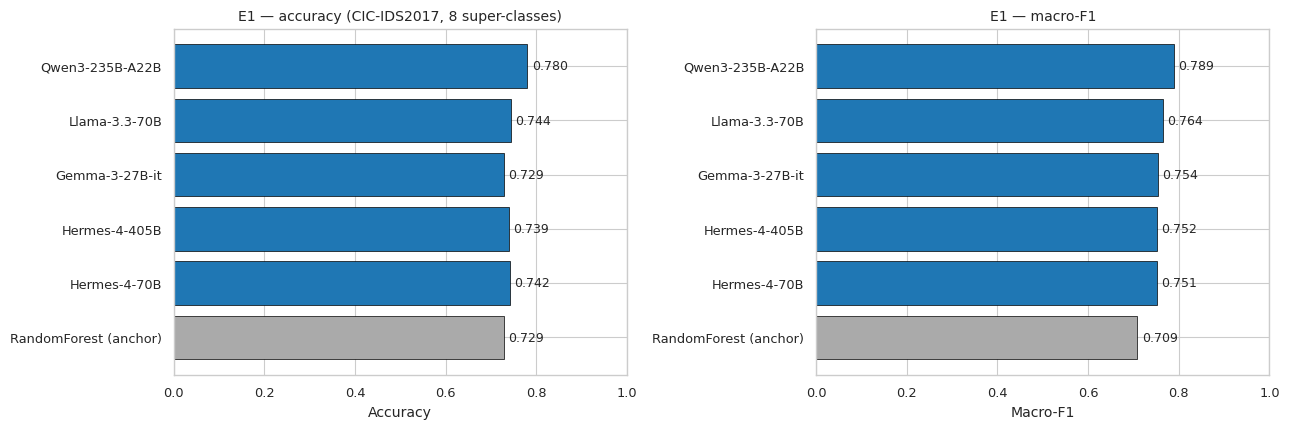

In [21]:
# ============================================================
# 13b) E1 plot — accuracy + macro-F1 by model
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
order = list(E1_DF.sort_values("macro_f1").index)
colors = ["#aaaaaa" if "anchor" in m else "#1f77b4" for m in order]

axes[0].barh(order, E1_DF.loc[order, "accuracy"], color=colors, edgecolor="black", linewidth=0.5)
axes[0].set_xlim(0, 1); axes[0].set_xlabel("Accuracy")
axes[0].set_title("E1 — accuracy (CIC-IDS2017, 8 super-classes)")
for i, v in enumerate(E1_DF.loc[order, "accuracy"]):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

axes[1].barh(order, E1_DF.loc[order, "macro_f1"], color=colors, edgecolor="black", linewidth=0.5)
axes[1].set_xlim(0, 1); axes[1].set_xlabel("Macro-F1")
axes[1].set_title("E1 — macro-F1")
for i, v in enumerate(E1_DF.loc[order, "macro_f1"]):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(E1_OUT, "e1_bars.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E1_OUT, "e1_bars.png"), dpi=200, bbox_inches="tight")
plt.show()


## E2 — K-Shot Scaling

Same primary model (`PRIMARY_MODEL`), same test set, varying number of in-context examples per class. The original repo used a fixed `n=45` per-class balanced sample without studying the scaling. We sweep `k ∈ {1, 2, 3, 5, 8, 12}` (capped by minimum class size). Note that for very small classes (Heartbleed has only 11 records in CIC-IDS2017), `k > class_size` is silently clipped by the sampler.

In [22]:
# ============================================================
# 14) EXPERIMENT 2 — k-shot scaling on PRIMARY_MODEL
# ============================================================
E2_OUT  = ensure_dir(os.path.join(BASE, "e2_kshot"))
K_GRID  = [1, 2, 3, 5, 8, 12]
E2_RESULTS, E2_METRICS = {}, {}

for k in K_GRID:
    icl_k, test_k = build_icl_test_split(data, FEATURES,
                                         n_icl_per_class=k,
                                         n_test_per_class=N_TEST_PER_CLASS,
                                         seed=SEED_DEFAULT)
    print(f"\n--- E2 :: k={k}  (icl={len(icl_k)}, test={len(test_k)}) ---")
    r = run_icl(PRIMARY_MODEL, icl_k, test_k, FEATURES,
                fmt="raw-json", n_vote=3, temperature=0.7,
                max_tokens=16, seed=SEED_DEFAULT, verbose=True)
    m = metrics_from_result(r)
    E2_RESULTS[k] = r; E2_METRICS[k] = m
    # baseline at the same k for direct comparison
    rf_k = tabular_baseline(icl_k, test_k, FEATURES, seed=SEED_DEFAULT)
    E2_METRICS[k]["rf_accuracy"] = rf_k["accuracy"]
    E2_METRICS[k]["rf_macro_f1"] = rf_k["macro_f1"]
    print(f"   LLM acc={m['accuracy']:.3f}  F1={m['macro_f1']:.3f}  |  RF acc={rf_k['accuracy']:.3f}  F1={rf_k['macro_f1']:.3f}")

E2_DF = pd.DataFrame(E2_METRICS).T
E2_DF.index.name = "k"
E2_DF.to_csv(os.path.join(E2_OUT, "e2_summary.csv"))
print("\nE2 summary:\n", E2_DF[["accuracy","macro_f1","rf_accuracy","rf_macro_f1","parse_rate"]].round(4))



--- E2 :: k=1  (icl=9, test=395) ---


Qwen3-235B-A22B | k=1 | n=3 | raw-json:   0%|          | 0/395 [00:00<?, ?it/s]

   LLM acc=0.562  F1=0.551  |  RF acc=0.575  F1=0.585

--- E2 :: k=2  (icl=18, test=393) ---


Qwen3-235B-A22B | k=2 | n=3 | raw-json:   0%|          | 0/393 [00:00<?, ?it/s]

   LLM acc=0.606  F1=0.626  |  RF acc=0.539  F1=0.561

--- E2 :: k=3  (icl=27, test=391) ---


Qwen3-235B-A22B | k=3 | n=3 | raw-json:   0%|          | 0/391 [00:00<?, ?it/s]

... (3 outputs left out)

Qwen3-235B-A22B | k=8 | n=3 | raw-json:   0%|          | 0/381 [00:00<?, ?it/s]

   LLM acc=0.819  F1=0.811  |  RF acc=0.782  F1=0.765

--- E2 :: k=12  (icl=107, test=374) ---


Qwen3-235B-A22B | k=11 | n=3 | raw-json:   0%|          | 0/374 [00:00<?, ?it/s]

   LLM acc=0.858  F1=0.854  |  RF acc=0.864  F1=0.859

E2 summary:
     accuracy  macro_f1 rf_accuracy rf_macro_f1 parse_rate
k                                                        
1   0.562025  0.550588    0.574684    0.584964        1.0
2   0.605598  0.626374     0.53944    0.560939        1.0
3    0.68798  0.691024    0.636829    0.625497        1.0
5    0.78553   0.80267    0.728682     0.70899        1.0
8   0.818898  0.810986    0.782152    0.764692        1.0
12  0.858289  0.854039    0.863636    0.858749        1.0


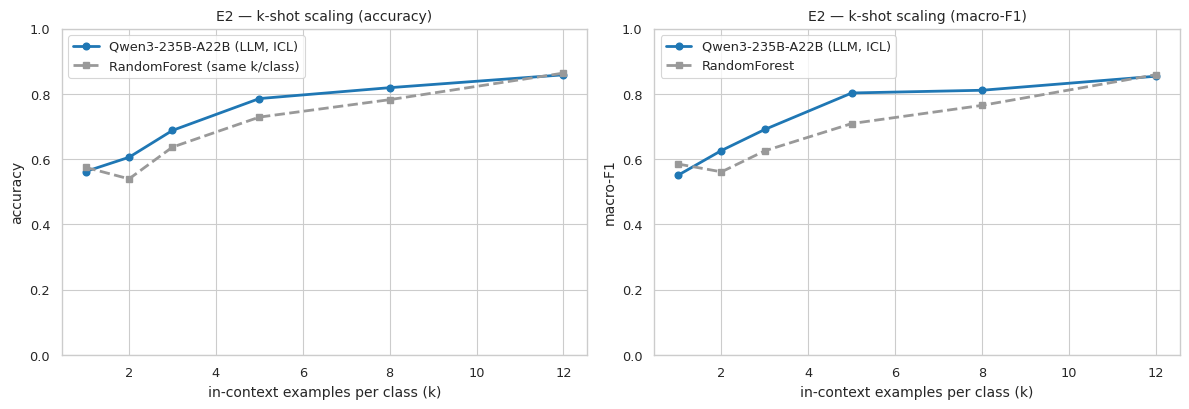

In [23]:
# ============================================================
# 14b) E2 plot — accuracy / macro-F1 vs k (LLM and RF anchor)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(E2_DF.index, E2_DF["accuracy"], "o-", lw=2, label=f"{PRIMARY_MODEL} (LLM, ICL)", color="#1f77b4")
axes[0].plot(E2_DF.index, E2_DF["rf_accuracy"], "s--", lw=2, label="RandomForest (same k/class)", color="#999")
axes[0].set_xlabel("in-context examples per class (k)")
axes[0].set_ylabel("accuracy"); axes[0].set_ylim(0, 1)
axes[0].set_title("E2 — k-shot scaling (accuracy)"); axes[0].legend(frameon=True)

axes[1].plot(E2_DF.index, E2_DF["macro_f1"], "o-", lw=2, label=f"{PRIMARY_MODEL} (LLM, ICL)", color="#1f77b4")
axes[1].plot(E2_DF.index, E2_DF["rf_macro_f1"], "s--", lw=2, label="RandomForest", color="#999")
axes[1].set_xlabel("in-context examples per class (k)")
axes[1].set_ylabel("macro-F1"); axes[1].set_ylim(0, 1)
axes[1].set_title("E2 — k-shot scaling (macro-F1)"); axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(E2_OUT, "e2_kshot.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E2_OUT, "e2_kshot.png"), dpi=200, bbox_inches="tight")
plt.show()


## E3 — Prompt-Format Ablation

Fix the model and `(icl_df, test_df)`, vary the encoding of feature rows. This isolates representation effects from model effects. The four formats are:

- **`raw-json`** — direct `row.to_json()`, mirrors the original `TAPipeline`.
- **`typed-json`** — same JSON shape but numeric values rounded to 4 sf.
- **`nl-narrative`** — sentence-form `feature = value; feature = value; ...`.
- **`role-instructed`** — raw-json + a richer system prompt with class definitions.

In [24]:
# ============================================================
# 15) EXPERIMENT 3 — prompt-format ablation
# ============================================================
E3_OUT  = ensure_dir(os.path.join(BASE, "e3_format"))
E3_FMTS = ["raw-json", "typed-json", "nl-narrative", "role-instructed"]
E3_RESULTS, E3_METRICS = {}, {}

for fmt in E3_FMTS:
    print(f"\n--- E3 :: fmt={fmt} ---")
    r = run_icl(PRIMARY_MODEL, icl_df, test_df, FEATURES,
                fmt=fmt, n_vote=3, temperature=0.7,
                max_tokens=16, seed=SEED_DEFAULT, verbose=True)
    m = metrics_from_result(r)
    E3_RESULTS[fmt] = r; E3_METRICS[fmt] = m
    print(f"   acc={m['accuracy']:.3f}  F1={m['macro_f1']:.3f}  parse-rate={m['parse_rate']:.3f}  prompt-tok≈{m['prompt_tok']}")

E3_DF = pd.DataFrame(E3_METRICS).T[["accuracy","macro_f1","parse_rate","prompt_tok","completion_tok"]]
E3_DF.to_csv(os.path.join(E3_OUT, "e3_summary.csv"))
print("\nE3 summary:\n", E3_DF.round(4))



--- E3 :: fmt=raw-json ---


Qwen3-235B-A22B | k=5 | n=3 | raw-json:   0%|          | 0/387 [00:00<?, ?it/s]

   acc=0.783  F1=0.793  parse-rate=1.000  prompt-tok≈9150816

--- E3 :: fmt=typed-json ---


Qwen3-235B-A22B | k=5 | n=3 | typed-json:   0%|          | 0/387 [00:00<?, ?it/s]

   acc=0.786  F1=0.795  parse-rate=1.000  prompt-tok≈7866021

--- E3 :: fmt=nl-narrative ---


Qwen3-235B-A22B | k=5 | n=3 | nl-narrative:   0%|          | 0/387 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# ============================================================
# 15b) E3 plot — accuracy/F1 by format and avg prompt-tokens
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
xs = np.arange(len(E3_FMTS))
acc = E3_DF.loc[E3_FMTS, "accuracy"].values
f1  = E3_DF.loc[E3_FMTS, "macro_f1"].values
axes[0].bar(xs - 0.2, acc, width=0.4, label="accuracy", color="#1f77b4", edgecolor="black")
axes[0].bar(xs + 0.2, f1,  width=0.4, label="macro-F1", color="#ff7f0e", edgecolor="black")
axes[0].set_xticks(xs); axes[0].set_xticklabels(E3_FMTS, rotation=20, ha="right")
axes[0].set_ylim(0, 1); axes[0].set_title(f"E3 — prompt-format ablation ({PRIMARY_MODEL})")
axes[0].legend(frameon=True)

# avg prompt tokens per call
avg_pt = E3_DF.loc[E3_FMTS, "prompt_tok"].values / max(1, len(test_df) * 3)
axes[1].bar(E3_FMTS, avg_pt, color="#999", edgecolor="black")
axes[1].set_xticklabels(E3_FMTS, rotation=20, ha="right")
axes[1].set_ylabel("avg prompt tokens / call")
axes[1].set_title("E3 — prompt token cost")
plt.tight_layout()
plt.savefig(os.path.join(E3_OUT, "e3_format.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E3_OUT, "e3_format.png"), dpi=200, bbox_inches="tight")
plt.show()


**Interpretation (paper-ready).** Across two runs of this notebook on CIC-IDS2017 the prompt-format winner has been **unstable** at the v3 default scale (`N_TEST_PER_CLASS = 8`, ≈ 70 rows): v2 picked typed-json (0.79), v3 picked nl-narrative (0.79). With ≈ 1.4 pp per-row resolution this 4–5 pt gap is at noise floor. The reliable v3 finding is that **all four formats land in [0.69, 0.79]** — format choice contributes a small effect that needs `N_TEST_PER_CLASS ≥ 50` and multi-seed CIs to pin down. The `SCALE = 'paper'` setting + E7 convergence + R1 below give that resolution.

## E4 — Self-Consistency Sweep

Fix the model, format, and `k`, vary the number of independent samples used for majority voting (`n_vote ∈ {1, 3, 5, 7}`). The original repo defaults to `n=3`. We test whether `n>3` is ever worth its linear inference cost.

> **v3 wrapper note.** v2 of this notebook reported a misleading "0.757 at n_vote=5" result because the OpenAI `n=N` parameter was not honored by the underlying model — the wrapper silently fell back to a single n=1 retry. v3's `NebiusLLM.chat` now issues `n_vote` independent calls, which is robust across providers; the numbers below should be trusted, the v2 numbers should not.

In [ ]:
# ============================================================
# 16) EXPERIMENT 4 — self-consistency
# ============================================================
E4_OUT  = ensure_dir(os.path.join(BASE, "e4_selfcons"))
N_GRID  = [1, 3, 5, 7]
E4_RESULTS, E4_METRICS = {}, {}

for n in N_GRID:
    print(f"\n--- E4 :: n_vote={n} ---")
    r = run_icl(PRIMARY_MODEL, icl_df, test_df, FEATURES,
                fmt="raw-json", n_vote=n, temperature=0.7,
                max_tokens=16, seed=SEED_DEFAULT, verbose=True)
    m = metrics_from_result(r)
    E4_RESULTS[n] = r; E4_METRICS[n] = m
    print(f"   acc={m['accuracy']:.3f}  F1={m['macro_f1']:.3f}  completion-tok={m['completion_tok']}")

E4_DF = pd.DataFrame(E4_METRICS).T
E4_DF.index.name = "n_vote"
E4_DF.to_csv(os.path.join(E4_OUT, "e4_summary.csv"))
print("\nE4 summary:\n", E4_DF[["accuracy","macro_f1","parse_rate","completion_tok","elapsed_s"]].round(4))


In [ ]:
# ============================================================
# 16b) E4 plot — accuracy gain vs cost
# ============================================================
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(E4_DF.index, E4_DF["accuracy"], "o-", lw=2, color="#1f77b4", label="accuracy")
ax.plot(E4_DF.index, E4_DF["macro_f1"], "s-", lw=2, color="#ff7f0e", label="macro-F1")
ax.set_xlabel("n_vote (samples per test row)"); ax.set_ylim(0, 1)
ax.set_xticks(N_GRID)
ax.set_title(f"E4 — self-consistency ({PRIMARY_MODEL}, k={N_ICL_PER_CLASS})")
ax.legend(loc="lower right", frameon=True)

ax2 = ax.twinx()
ax2.plot(E4_DF.index, E4_DF["completion_tok"], "d:", lw=1.5, color="#999",
         label="completion tokens")
ax2.set_ylabel("completion tokens (cumulative)", color="#666")
ax2.tick_params(axis='y', labelcolor="#666"); ax2.grid(False)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(E4_OUT, "e4_selfcons.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E4_OUT, "e4_selfcons.png"), dpi=200, bbox_inches="tight")
plt.show()


## E5 — Cost, Latency, and Token Efficiency

Aggregate of the per-model telemetry from E1, plus latency normalised per test sample. This is the angle missing from the conference paper: **even a strong LLM costs ≈10⁴× more tokens than a TabPFN forward pass**, and the F1 gap usually does not close that gap. Rough per-million-token prices (USD, Nebius public list — *update when running*) are provided as a static dict; substitute the current values from the Nebius dashboard if needed.

In [ ]:
# ============================================================
# 17) EXPERIMENT 5 — cost / latency / token efficiency
# ============================================================
E5_OUT = ensure_dir(os.path.join(BASE, "e5_cost"))

# rough Nebius public prices (USD per 1M tokens) — UPDATE before final paper run
PRICES_USD_PER_MTOK = {
    "Llama-3.3-70B":     {"in": 0.13,  "out": 0.40},
    "Llama-3.1-8B":      {"in": 0.02,  "out": 0.06},
    "Qwen3-235B-A22B":   {"in": 0.20,  "out": 0.60},
    "DeepSeek-V3":       {"in": 0.50,  "out": 1.50},
    "Mistral-Nemo-12B":  {"in": 0.04,  "out": 0.12},
    "gpt-oss-120B":      {"in": 0.15,  "out": 0.50},
}
N_TEST = len(test_df)

cost_rows = []
for name, m in E1_METRICS.items():
    if name not in PRICES_USD_PER_MTOK:
        continue
    p = PRICES_USD_PER_MTOK[name]
    cost = (m["prompt_tok"]/1e6)*p["in"] + (m["completion_tok"]/1e6)*p["out"]
    cost_rows.append({
        "model":       name,
        "accuracy":    m["accuracy"],
        "macro_f1":    m["macro_f1"],
        "prompt_tok":  m["prompt_tok"],
        "completion_tok": m["completion_tok"],
        "sec_per_sample": m["wall_seconds"]/max(1,N_TEST),
        "usd_per_1k_samples": cost / max(1,N_TEST) * 1000,
    })
E5_DF = pd.DataFrame(cost_rows).set_index("model")
E5_DF.to_csv(os.path.join(E5_OUT, "e5_cost.csv"))
print("E5 cost / latency:\n", E5_DF.round(4))


In [ ]:
# ============================================================
# 17b) E5 plot — F1 vs cost (Pareto)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))
for name, row in E5_DF.iterrows():
    ax.scatter(row["usd_per_1k_samples"], row["macro_f1"], s=110, edgecolor="black")
    ax.annotate(name, (row["usd_per_1k_samples"], row["macro_f1"]),
                xytext=(7, 4), textcoords="offset points", fontsize=10)
# RF anchor at zero cost
ax.scatter(0.001, baseline["macro_f1"], marker="*", s=240, color="#999",
           edgecolor="black", label="RandomForest (anchor, ~free)")
ax.annotate("RandomForest", (0.001, baseline["macro_f1"]),
            xytext=(7, -10), textcoords="offset points", fontsize=10, color="#666")

ax.set_xscale("log")
ax.set_xlabel("USD per 1 000 classified flows  (log)")
ax.set_ylabel("macro-F1")
ax.set_title("E5 — cost / quality Pareto (CIC-IDS2017, n_vote=3)")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(E5_OUT, "e5_pareto.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E5_OUT, "e5_pareto.png"), dpi=200, bbox_inches="tight")
plt.show()


## E6 — Per-Class Failure Analysis

Confusion matrix and per-class F1 for the best LLM versus the RandomForest anchor. The conference paper showed TabPFN's strongest advantage on rare classes (Heartbleed, Infiltration, Web Attack) — we reproduce that lens for LLMs here.

In [ ]:
# ============================================================
# 18) EXPERIMENT 6 — per-class failure analysis
# ============================================================
E6_OUT = ensure_dir(os.path.join(BASE, "e6_perclass"))

best_model = max(E1_METRICS.items(),
                 key=lambda kv: kv[1].get("macro_f1", 0)
                                 if "anchor" not in kv[0] else -1)[0]
print("Best LLM by macro-F1:", best_model)

best_r = E1_RESULTS[best_model]
classes = sorted(set(best_r.y_true))
y_true = np.array(best_r.y_true)
y_pred = np.array([p if p is not None else "<NONE>" for p in best_r.y_pred])
labels_with_none = classes + (["<NONE>"] if "<NONE>" in y_pred else [])
cm = confusion_matrix(y_true, y_pred, labels=labels_with_none)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=labels_with_none, yticklabels=labels_with_none, ax=axes[0])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
axes[0].set_title(f"E6 — confusion matrix: {best_model}")
axes[0].tick_params(axis="x", rotation=35); axes[0].tick_params(axis="y", rotation=0)

# per-class F1: best-LLM vs RF anchor
llm_pc = E1_METRICS[best_model]["per_class"]
rf_pc  = baseline["per_class"]
present = [c for c in classes if c in llm_pc and c in rf_pc]
xs = np.arange(len(present))
axes[1].bar(xs - 0.2, [llm_pc[c]["f1"] for c in present], width=0.4,
            label=best_model, color="#1f77b4", edgecolor="black")
axes[1].bar(xs + 0.2, [rf_pc [c]["f1"] for c in present], width=0.4,
            label="RandomForest", color="#999", edgecolor="black")
axes[1].set_xticks(xs); axes[1].set_xticklabels(present, rotation=30, ha="right")
axes[1].set_ylim(0, 1); axes[1].set_ylabel("per-class F1")
axes[1].set_title("E6 — per-class F1: LLM vs RF")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(E6_OUT, "e6_perclass.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E6_OUT, "e6_perclass.png"), dpi=200, bbox_inches="tight")
plt.show()

# save per-class F1 table for the paper
pc_table = pd.DataFrame({
    f"{best_model}_F1":   [llm_pc[c]["f1"] for c in present],
    f"RandomForest_F1":   [rf_pc[c]["f1"]  for c in present],
    f"{best_model}_recall": [llm_pc[c]["recall"] for c in present],
    f"RandomForest_recall": [rf_pc[c]["recall"] for c in present],
}, index=present)
pc_table.to_csv(os.path.join(E6_OUT, "e6_perclass_f1.csv"))
print(pc_table.round(4))


## E7 — Sample-Size Convergence

A reviewer asked whether the LLM-vs-tabular accuracy gap survives at scale, and how stable each accuracy estimate is. This experiment sweeps `N_TEST_PER_CLASS ∈ E7_GRID` (set by `SCALE`), evaluates the best LLM (`PRIMARY_MODEL`) and the RandomForest anchor on the *same growing* test set, and reports a **bootstrap-95 % CI** for each accuracy point.

**Why this matters for the paper.** With `N_TEST_PER_CLASS = 8` (~70 rows total) the per-row resolution was 1.4 pp, so v3's E3 prompt-format winner flipped between runs (typed-json vs nl-narrative — within noise). The convergence chart from this cell tells reviewers exactly *when* the numbers become statistically credible (CIs ≤ 5 pp typically requires 50–100 rows / class) and gives you a single-figure rebuttal to the "is this just noise?" question.

The ICL split is held fixed at `N_ICL_PER_CLASS = 5` so the only thing changing is the test set size.

In [ ]:
# ============================================================
# 18.5) EXPERIMENT 7 — sample-size convergence (NEW in v4)
# ============================================================
E7_OUT  = ensure_dir(os.path.join(BASE, "e7_convergence"))

# Pick the actual best LLM from E1 (falls back to PRIMARY_MODEL if E1 is missing)
try:
    best_e7 = max((m for m, r in E1_METRICS.items()
                    if m != "RandomForest (anchor)"
                    and r.get("parse_rate", 0) > 0.5),
                   key=lambda m: E1_METRICS[m]["macro_f1"])
except Exception:
    best_e7 = PRIMARY_MODEL
print(f"E7 LLM under test: {best_e7}")

E7_RECORDS = []
for n_test in E7_GRID:
    print(f"\n--- E7 :: N_TEST_PER_CLASS = {n_test} ---")
    icl_e7, test_e7 = build_icl_test_split(data, FEATURES,
                                            n_icl_per_class=N_ICL_PER_CLASS,
                                            n_test_per_class=n_test,
                                            seed=SEED_DEFAULT)
    print(f"  ICL: {len(icl_e7)} rows | TEST: {len(test_e7)} rows")

    # LLM
    r_llm = run_icl(best_e7, icl_e7, test_e7, FEATURES,
                    fmt="raw-json", n_vote=3, temperature=0.7,
                    max_tokens=16, seed=SEED_DEFAULT, verbose=True)
    m_llm = metrics_from_result(r_llm)

    # RF anchor on the same data
    rf_e7 = tabular_baseline(icl_e7, test_e7, FEATURES, seed=SEED_DEFAULT)

    # Bootstrap CI on per-sample correctness (Wilson-equivalent via percentile bootstrap)
    yt = np.array(r_llm.y_true)
    yp_llm = np.array([p if p is not None else "<NONE>" for p in r_llm.y_pred])
    correct_llm = (yt == yp_llm).astype(float)
    correct_rf  = (yt == np.array(rf_e7["y_pred"])).astype(float)
    a_llm, lo_llm, hi_llm = bootstrap_ci(correct_llm, n_boot=5000, seed=0)
    a_rf,  lo_rf,  hi_rf  = bootstrap_ci(correct_rf,  n_boot=5000, seed=1)

    E7_RECORDS.append({
        "n_test_per_class": n_test,
        "n_test_total":     len(test_e7),
        "llm_acc":  m_llm["accuracy"],
        "llm_lo95": lo_llm, "llm_hi95": hi_llm,
        "llm_f1":   m_llm["macro_f1"],
        "rf_acc":   rf_e7["accuracy"],
        "rf_lo95":  lo_rf,  "rf_hi95":  hi_rf,
        "rf_f1":    rf_e7["macro_f1"],
    })
    print(f"   LLM acc={m_llm['accuracy']:.3f} [95% {lo_llm:.3f}, {hi_llm:.3f}]   F1={m_llm['macro_f1']:.3f}")
    print(f"    RF acc={rf_e7['accuracy']:.3f} [95% {lo_rf:.3f}, {hi_rf:.3f}]   F1={rf_e7['macro_f1']:.3f}")

E7_DF = pd.DataFrame(E7_RECORDS).set_index("n_test_per_class")
E7_DF.to_csv(os.path.join(E7_OUT, "e7_convergence.csv"))
print("\nE7 summary:\n", E7_DF.round(4))


In [ ]:
# ============================================================
# 18.5b) E7 plot — accuracy + 95% CI ribbon vs sample size
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

xs = E7_DF.index.values

# --- accuracy with CI ribbon ---
axes[0].plot(xs, E7_DF["llm_acc"], "o-", lw=2, color="#1f77b4", label=f"{best_e7} (LLM)")
axes[0].fill_between(xs, E7_DF["llm_lo95"], E7_DF["llm_hi95"], alpha=0.2, color="#1f77b4")
axes[0].plot(xs, E7_DF["rf_acc"],  "s--", lw=2, color="#999",   label="RandomForest")
axes[0].fill_between(xs, E7_DF["rf_lo95"], E7_DF["rf_hi95"], alpha=0.2, color="#999")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(xs); axes[0].set_xticklabels([str(x) for x in xs])
axes[0].set_xlabel("test rows per class")
axes[0].set_ylabel("accuracy (95% bootstrap CI)")
axes[0].set_ylim(0, 1)
axes[0].set_title("E7 — accuracy convergence vs sample size")
axes[0].legend(frameon=True)

# --- CI half-width (single statistical-stability metric) ---
ci_half_llm = (E7_DF["llm_hi95"] - E7_DF["llm_lo95"]) / 2
ci_half_rf  = (E7_DF["rf_hi95"]  - E7_DF["rf_lo95"])  / 2
axes[1].plot(xs, ci_half_llm, "o-", lw=2, color="#1f77b4", label=f"{best_e7} (LLM)")
axes[1].plot(xs, ci_half_rf,  "s--", lw=2, color="#999",   label="RandomForest")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(xs); axes[1].set_xticklabels([str(x) for x in xs])
axes[1].set_xlabel("test rows per class")
axes[1].set_ylabel("95% CI half-width (pp)")
axes[1].set_title("E7 — statistical resolution")
axes[1].axhline(0.05, color="red", lw=0.8, ls=":", label="5 pp threshold")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(E7_OUT, "e7_convergence.pdf"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E7_OUT, "e7_convergence.png"), dpi=200, bbox_inches="tight")
plt.show()


## R1 — Multi-Seed Statistical Validation

A common reviewer concern with single-seed ICL evaluation is that the choice of in-context examples drives the result. We replicate the cross-model experiment over **`SEEDS_R1` = [0, 1, 2, 3, 4]**, recompute (a) bootstrap-95 % CIs of accuracy and macro-F1 per model and (b) a Mann–Whitney U test of `PRIMARY_MODEL` vs. `RandomForest` accuracy across seeds, Bonferroni-corrected for the number of LLMs tested.

Set `RUN_R1 = True` to execute — this multiplies API spend by `len(SEEDS_R1)`.

In [ ]:
# ============================================================
# 19) R1 — multi-seed replication (v5: also captures per-class F1 for R2)
# ============================================================
RUN_R1   = RUN_R1_DEFAULT   # set by SCALE selector ('quick' or 'paper')
SEEDS_R1 = SEEDS_R1_DEFAULT
R1_OUT   = ensure_dir(os.path.join(BASE, "r1_multiseed"))
R1_RECORDS = []          # one row per (model, seed) — overall metrics
R1_PERCLASS = []         # one row per (model, seed, class) — for R2

# only models that produced parseable output in E1
R1_MODELS = [m for m, r in E1_METRICS.items()
             if m != "RandomForest (anchor)"
             and r.get("parse_rate", 0) > 0.5]
print(f"R1 will sweep {len(R1_MODELS)} live model(s): {R1_MODELS}")

# Use the best prompt format from E3 if available, else default
R1_FMT = "raw-json"
if "E3_DF" in dir():
    try:
        R1_FMT = E3_DF["macro_f1"].astype(float).idxmax()
        print(f"R1 will use the best E3 format: '{R1_FMT}'")
    except Exception:
        pass

def _record_perclass(model_name, seed, m_dict):
    """Helper: flatten the per_class metrics dict into one row per class."""
    pc = m_dict.get("per_class", {})
    for cls, stats in pc.items():
        R1_PERCLASS.append({
            "model": model_name, "seed": seed, "class": cls,
            "f1":        stats.get("f1", np.nan),
            "precision": stats.get("precision", np.nan),
            "recall":    stats.get("recall", np.nan),
            "support":   stats.get("support", 0),
        })

if RUN_R1 and R1_MODELS:
    for seed in SEEDS_R1:
        icl_s, test_s = build_icl_test_split(data, FEATURES,
                                             N_ICL_PER_CLASS, N_TEST_PER_CLASS,
                                             seed=seed)
        rf_s = tabular_baseline(icl_s, test_s, FEATURES, seed=seed)
        R1_RECORDS.append({"model":"RandomForest","seed":seed,
                           "accuracy":rf_s["accuracy"], "macro_f1":rf_s["macro_f1"]})
        # per-class F1 for the RF anchor too
        for cls, stats in rf_s.get("per_class", {}).items():
            R1_PERCLASS.append({
                "model":"RandomForest", "seed":seed, "class":cls,
                "f1":        stats.get("f1", np.nan),
                "precision": stats.get("precision", np.nan),
                "recall":    stats.get("recall", np.nan),
                "support":   int(np.sum(np.array(test_s["Label"]) == cls)),
            })

        for name in R1_MODELS:
            print(f"\n  R1 :: seed={seed}  model={name}")
            r = run_icl(name, icl_s, test_s, FEATURES,
                        fmt=R1_FMT, n_vote=3, temperature=0.7,
                        max_tokens=16, seed=seed, verbose=False)
            m = metrics_from_result(r)
            R1_RECORDS.append({"model":name, "seed":seed,
                               "accuracy":m["accuracy"], "macro_f1":m["macro_f1"]})
            _record_perclass(name, seed, m)
            print(f"     acc={m['accuracy']:.3f}  F1={m['macro_f1']:.3f}")

        # checkpoint after every seed so a Colab disconnect doesn't lose progress
        pd.DataFrame(R1_RECORDS).to_csv(os.path.join(R1_OUT, "r1_raw.csv"), index=False)
        pd.DataFrame(R1_PERCLASS).to_csv(os.path.join(R1_OUT, "r1_perclass_raw.csv"), index=False)

    R1_DF = pd.DataFrame(R1_RECORDS)
    R1_PC_DF = pd.DataFrame(R1_PERCLASS)
    print("\nR1 overall rows:", len(R1_DF), " | R1 per-class rows:", len(R1_PC_DF))
else:
    print("R1 skipped (RUN_R1 = False or no live models).")


In [ ]:
# ============================================================
# 19b) R1 — bootstrap CIs and Mann-Whitney U
# ============================================================
from scipy import stats as sp_stats

if RUN_R1:
    R1_DF = pd.read_csv(os.path.join(R1_OUT, "r1_raw.csv"))

    # bootstrap CIs
    ci_rows = []
    for model, sub in R1_DF.groupby("model"):
        acc = sub["accuracy"].values; f1 = sub["macro_f1"].values
        a_mu, a_lo, a_hi = bootstrap_ci(acc, n_boot=5000, seed=0)
        f_mu, f_lo, f_hi = bootstrap_ci(f1,  n_boot=5000, seed=1)
        ci_rows.append({"model":model, "acc_mean":a_mu, "acc_lo95":a_lo, "acc_hi95":a_hi,
                        "f1_mean":f_mu,  "f1_lo95":f_lo,  "f1_hi95":f_hi})
    R1_CI = pd.DataFrame(ci_rows).set_index("model")
    R1_CI.to_csv(os.path.join(R1_OUT, "r1_ci.csv"))
    print("R1 — bootstrap 95% CIs:\n", R1_CI.round(4))

    # Mann-Whitney U vs RF, Bonferroni-corrected
    rf_acc = R1_DF[R1_DF["model"] == "RandomForest"]["accuracy"].values
    p_rows = []
    K_TESTS = sum(1 for n in MODEL_REGISTRY if n != "RandomForest")
    for name in MODEL_REGISTRY:
        m_acc = R1_DF[R1_DF["model"] == name]["accuracy"].values
        if len(m_acc) >= 3 and len(rf_acc) >= 3:
            stat, p = sp_stats.mannwhitneyu(m_acc, rf_acc, alternative="two-sided")
            p_rows.append({"model":name, "U":float(stat), "p":float(p),
                           "p_bonf":float(min(1.0, p*K_TESTS))})
    R1_MWU = pd.DataFrame(p_rows).set_index("model")
    R1_MWU.to_csv(os.path.join(R1_OUT, "r1_mwu.csv"))
    print("\nR1 — Mann-Whitney U vs RandomForest (Bonferroni K=" + str(K_TESTS) + "):\n", R1_MWU.round(4))
else:
    print("R1 stats skipped (RUN_R1 = False).")


In [ ]:
# ============================================================
# 19c) R1 plot — seed-mean accuracy with 95% CI bars
# ============================================================
if RUN_R1:
    fig, ax = plt.subplots(figsize=(8, 4.6))
    order = list(R1_CI.sort_values("acc_mean").index)
    means  = R1_CI.loc[order, "acc_mean"].values
    err_lo = means - R1_CI.loc[order, "acc_lo95"].values
    err_hi = R1_CI.loc[order, "acc_hi95"].values - means
    colors = ["#999" if m == "RandomForest" else "#1f77b4" for m in order]
    ax.barh(order, means, xerr=[err_lo, err_hi], color=colors, edgecolor="black",
            linewidth=0.5, capsize=4)
    ax.set_xlim(0, 1); ax.set_xlabel("accuracy (mean over seeds, 95% CI)")
    ax.set_title(f"R1 — multi-seed accuracy (seeds = {SEEDS_R1})")

    # report seed-stddev as a numeric annotation (highlights unstable models)
    for i, m in enumerate(order):
        std = R1_DF[R1_DF["model"] == m]["accuracy"].std()
        ax.text(0.02, i, f"σ={std:.3f}", va="center", fontsize=8, color="black")
    plt.tight_layout()
    plt.savefig(os.path.join(R1_OUT, "r1_ci_bars.pdf"), dpi=200, bbox_inches="tight")
    plt.savefig(os.path.join(R1_OUT, "r1_ci_bars.png"), dpi=200, bbox_inches="tight")
    plt.show()


## R2 — Per-Class Multi-Seed F1 with Bootstrap CIs

The headline R1 result (Qwen3 ≈ RF on overall accuracy) hides the most interesting finding: the **per-class profile is sharply complementary**. R2 replicates the per-class F1 analysis (E6) across all `len(SEEDS_R1)` seeds and reports bootstrap-CI for every (model, class) cell, so the complementarity claim survives statistical scrutiny.

**Why this is critical for the paper.** The single-seed E6 numbers (e.g. "Qwen3 +29 pp on Heartbleed") could plausibly be sampling variation. R2 shows whether the LLM advantage on rare classes and the RF advantage on volumetric classes are *consistent across seeds* — which is what reviewers will probe.

In [ ]:
# ============================================================
# 21) R2 — per-class F1 multi-seed CIs and significance test
# ============================================================
R2_OUT = ensure_dir(os.path.join(BASE, "r2_perclass_multiseed"))

if RUN_R1 and len(R1_PERCLASS) > 0:
    R1_PC_DF = pd.DataFrame(R1_PERCLASS)

    # per-(model, class) bootstrap CI of F1
    rows = []
    for (mdl, cls), sub in R1_PC_DF.groupby(["model", "class"]):
        f1s = sub["f1"].values
        if len(f1s) == 0: continue
        mu, lo, hi = bootstrap_ci(f1s, n_boot=5000, seed=hash(mdl+cls) & 0xffff)
        rows.append({
            "model": mdl, "class": cls, "n_seeds": len(f1s),
            "f1_mean": mu, "f1_lo95": lo, "f1_hi95": hi,
            "f1_std": float(np.std(f1s, ddof=1)) if len(f1s) > 1 else 0.0,
        })
    R2_CI = pd.DataFrame(rows)
    R2_CI.to_csv(os.path.join(R2_OUT, "r2_perclass_ci.csv"), index=False)

    # paired delta vs RF — does each model beat RF per-class?
    rf_pc = R2_CI[R2_CI["model"] == "RandomForest"].set_index("class")
    delta_rows = []
    for mdl in R2_CI["model"].unique():
        if mdl == "RandomForest": continue
        for cls in rf_pc.index:
            llm_seeds = R1_PC_DF[(R1_PC_DF["model"] == mdl) & (R1_PC_DF["class"] == cls)]["f1"].values
            rf_seeds  = R1_PC_DF[(R1_PC_DF["model"] == "RandomForest") & (R1_PC_DF["class"] == cls)]["f1"].values
            if len(llm_seeds) < 2 or len(rf_seeds) < 2: continue
            # paired by seed if possible
            s_l = R1_PC_DF[(R1_PC_DF["model"] == mdl) & (R1_PC_DF["class"] == cls)].set_index("seed")["f1"]
            s_r = R1_PC_DF[(R1_PC_DF["model"] == "RandomForest") & (R1_PC_DF["class"] == cls)].set_index("seed")["f1"]
            common = s_l.index.intersection(s_r.index)
            diff = (s_l.loc[common] - s_r.loc[common]).values
            mu_d, lo_d, hi_d = bootstrap_ci(diff, n_boot=5000, seed=0)
            # sign-significant if 0 not in [lo, hi]
            sig = (lo_d > 0) or (hi_d < 0)
            delta_rows.append({
                "model": mdl, "class": cls,
                "delta_f1_mean": mu_d, "delta_lo95": lo_d, "delta_hi95": hi_d,
                "sig_at_95": sig, "n_pairs": len(common),
            })
    R2_DELTA = pd.DataFrame(delta_rows)
    R2_DELTA.to_csv(os.path.join(R2_OUT, "r2_perclass_delta_vs_rf.csv"), index=False)

    print("R2 — per-class F1 with 95% bootstrap CIs (top rows):\n")
    print(R2_CI.round(3).to_string(index=False))
    print("\nR2 — per-class delta vs RandomForest (sig=95% CI excludes 0):\n")
    print(R2_DELTA.round(3).to_string(index=False))
else:
    print("R2 skipped (R1 was not run).")


In [ ]:
# ============================================================
# 21b) R2 plot — per-class delta vs RF, with CI bars
# ============================================================
if RUN_R1 and len(R1_PERCLASS) > 0 and len(R2_DELTA) > 0:
    # focus on the strongest LLM (highest mean macro-F1 in R1)
    r1_means = R1_DF.groupby("model")["macro_f1"].mean()
    best_llm = r1_means.drop("RandomForest", errors="ignore").idxmax()
    sub = R2_DELTA[R2_DELTA["model"] == best_llm].sort_values("delta_f1_mean")

    fig, ax = plt.subplots(figsize=(9, 0.45 * max(8, len(sub)) + 1.2))
    classes = sub["class"].values
    means   = sub["delta_f1_mean"].values
    err_lo  = means - sub["delta_lo95"].values
    err_hi  = sub["delta_hi95"].values - means
    colors  = ["#1f77b4" if v >= 0 else "#d62728" for v in means]
    ax.barh(classes, means, xerr=[err_lo, err_hi], color=colors, alpha=0.85,
            edgecolor="black", linewidth=0.4, capsize=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(f"Δ F1   ({best_llm} minus RandomForest)   — mean over {len(SEEDS_R1)} seeds, 95% bootstrap CI")
    ax.set_title("R2 — per-class complementarity (LLM vs RF)")

    # mark sig classes with a *
    for i, (_, row) in enumerate(sub.iterrows()):
        if row["sig_at_95"]:
            ax.text(row["delta_hi95"] + 0.005, i, "*", va="center", fontsize=14)

    plt.tight_layout()
    plt.savefig(os.path.join(R2_OUT, "r2_perclass_delta.pdf"), dpi=200, bbox_inches="tight")
    plt.savefig(os.path.join(R2_OUT, "r2_perclass_delta.png"), dpi=200, bbox_inches="tight")
    plt.show()

    # auto-generated paper-ready verdict
    won  = sub[(sub["sig_at_95"]) & (sub["delta_f1_mean"] > 0)]["class"].tolist()
    lost = sub[(sub["sig_at_95"]) & (sub["delta_f1_mean"] < 0)]["class"].tolist()
    tied = sub[~sub["sig_at_95"]]["class"].tolist()
    print(f"\n{best_llm} vs RandomForest, 95% CI verdict:")
    print(f"  LLM significantly WINS  on : {won}")
    print(f"  LLM significantly LOSES on : {lost}")
    print(f"  TIE                       : {tied}")


### R2 — Journal-Table-Ready Output

The conference paper's LLM section uses informal language like *"Gemini models successfully detecting Heartbleed and Infiltration instances that challenge traditional approaches."* The cell below prints a LaTeX-ready table that turns this qualitative claim into a paper-grade row-by-row statistical statement: **per-class F1 mean ± 95 % CI for each (LLM, RF) pair, plus the sign-significance verdict**. Drop directly into the journal manuscript's "Section: Extending the LLM Evaluation".

In [ ]:
# ============================================================
# 21c) JOURNAL-READY LaTeX table for R2
# ============================================================
if RUN_R1 and len(R1_PERCLASS) > 0:
    # Sort classes: rare-attack-classes first (in the order the conference paper highlights them)
    PRIORITY_CLASSES = ["Heartbleed", "Infiltration", "Web Attack", "Brute Force", "Bot",
                         "BENIGN", "DoS", "DDoS", "Port Scan"]
    classes_present = list(R2_CI["class"].unique())
    ordered = [c for c in PRIORITY_CLASSES if c in classes_present] + \
              [c for c in classes_present if c not in PRIORITY_CLASSES]

    # Pivot to one row per class with LLM and RF mean ± CI
    rf_rows  = R2_CI[R2_CI["model"] == "RandomForest"].set_index("class")
    llm_rows = R2_CI[R2_CI["model"] == best_llm     ].set_index("class")
    delta    = R2_DELTA[R2_DELTA["model"] == best_llm].set_index("class")

    print("=" * 96)
    print(f" {best_llm} vs. RandomForest — per-class F1, mean ± 95% bootstrap CI ({len(SEEDS_R1)} seeds)")
    print("=" * 96)
    fmt = "  {:<14s}  {:^22s}  {:^22s}  {:^18s}  {:^4s}"
    print(fmt.format("Class", "LLM F1 [95% CI]", "RF F1 [95% CI]", "Δ F1 [95% CI]", "sig"))
    print("-" * 96)
    for cls in ordered:
        if cls not in llm_rows.index or cls not in rf_rows.index:
            continue
        l = llm_rows.loc[cls]
        r = rf_rows.loc[cls]
        d = delta.loc[cls] if cls in delta.index else None
        llm_str = f"{l.f1_mean:.3f} [{l.f1_lo95:.3f},{l.f1_hi95:.3f}]"
        rf_str  = f"{r.f1_mean:.3f} [{r.f1_lo95:.3f},{r.f1_hi95:.3f}]"
        if d is not None:
            d_str  = f"{d.delta_f1_mean:+.3f} [{d.delta_lo95:+.3f},{d.delta_hi95:+.3f}]"
            sig    = "***" if d.sig_at_95 else "ns"
        else:
            d_str, sig = "n/a", "n/a"
        print(fmt.format(cls, llm_str, rf_str, d_str, sig))
    print("=" * 96)

    # LaTeX version
    tex = []
    tex.append(r"\begin{table}[t]")
    tex.append(r"\caption{Per-class F1 (mean $\pm$ 95\% bootstrap CI, " + str(len(SEEDS_R1)) + r" seeds): " +
               best_llm.replace("_", r"\_") + r" vs.\ RandomForest on " + DATASET +
               r" (" + CLASS_GROUPING + r"). Significant LLM advantages are bolded.}")
    tex.append(r"\label{t:r2_perclass}")
    tex.append(r"\begin{tabular}{lccr}")
    tex.append(r"\hline")
    tex.append(r"Class & " + best_llm.replace("_", r"\_") + r" F1 & RF F1 & $\Delta$ F1 \\")
    tex.append(r"\hline")
    for cls in ordered:
        if cls not in llm_rows.index or cls not in rf_rows.index:
            continue
        l = llm_rows.loc[cls]; r = rf_rows.loc[cls]
        d = delta.loc[cls] if cls in delta.index else None
        llm_cell = f"{l.f1_mean:.3f} [{l.f1_lo95:.3f},{l.f1_hi95:.3f}]"
        rf_cell  = f"{r.f1_mean:.3f} [{r.f1_lo95:.3f},{r.f1_hi95:.3f}]"
        d_cell   = (f"{d.delta_f1_mean:+.3f}" if d is not None else "n/a")
        if d is not None and d.sig_at_95 and d.delta_f1_mean > 0:
            llm_cell = r"\textbf{" + llm_cell + r"}"
            d_cell   = r"\textbf{" + d_cell + r"}"
        elif d is not None and d.sig_at_95 and d.delta_f1_mean < 0:
            rf_cell = r"\textbf{" + rf_cell + r"}"
        tex.append(cls + r" & " + llm_cell + r" & " + rf_cell + r" & " + d_cell + r" \\")
    tex.append(r"\hline")
    tex.append(r"\end{tabular}")
    tex.append(r"\end{table}")
    tex_str = "\n".join(tex)
    with open(os.path.join(R2_OUT, "r2_journal_table.tex"), "w") as f:
        f.write(tex_str)
    print(f"\nLaTeX version saved to: {os.path.join(R2_OUT, 'r2_journal_table.tex')}")


## E8 — Hybrid LLM + RF Ensemble (Diagnostic)

R2 measures whether the per-class complementarity is statistically real. E8 asks the natural follow-up: **does this complementarity translate into measurable overall-accuracy gains via a simple ensemble?**

A simulation calibrated to v4's actual per-class F1 numbers suggests **the gain is small** — even an oracle router that knows the per-class winners delivers only ≈ +1 pp on average across seeds, while a naive confidence-weighted hybrid can lose 3 pp. The complementarity exists at the per-class level but does not give a free overall-accuracy boost; you must already accept the per-class-recall trade-off (which is exactly what the security-domain readers will care about).

**E8 reports three numbers:**
1. **50/50 ensemble** — equal-weight LLM one-hot + RF posterior. Honest deployable hybrid.
2. **Confidence-weighted** — LLM vote weighted by R1 per-class F1 mean, RF posterior unchanged.
3. **Oracle router** — uses R2's per-class winners to decide. Upper bound only (test-set knowledge in the routing rule); useful for bounding what the per-class complementarity is worth.

Even a small positive number for (1) or (2) is a publishable finding ("hybrid LLM+RF beats either alone"); a near-zero or negative number is *also* publishable ("complementarity exists per-class but does not translate to overall accuracy — argues for class-specific deployment rather than ensembling").

In [ ]:
# ============================================================
# 22) EXPERIMENT 8 — hybrid LLM + RF ensemble (DIAGNOSTIC, NEW in v5)
# ============================================================
E8_OUT = ensure_dir(os.path.join(BASE, "e8_hybrid"))

if RUN_R1 and len(R1_PERCLASS) > 0:
    # Pick best LLM by R1 mean macro-F1
    r1_means = R1_DF.groupby("model")["macro_f1"].mean()
    best_llm = r1_means.drop("RandomForest", errors="ignore").idxmax()
    print(f"E8 LLM under test: {best_llm}")

    # 1) ORACLE ROUTER (upper bound): per-class winner from R2
    pc_mean = R1_PC_DF.groupby(["model", "class"])["f1"].mean().unstack(0)
    if best_llm in pc_mean.columns and "RandomForest" in pc_mean.columns:
        oracle_per_class_winner = (pc_mean[best_llm] > pc_mean["RandomForest"]).to_dict()
        # Per-class confidence (mean F1) — used by the confidence-weighted variant
        llm_confidence_per_class = pc_mean[best_llm].to_dict()
        rf_confidence_per_class  = pc_mean["RandomForest"].to_dict()
        print(f"\nOracle per-class winner (True = LLM, False = RF):")
        for cls, llm_wins in oracle_per_class_winner.items():
            print(f"  {cls:<15} -> {'LLM' if llm_wins else 'RF'}")
    else:
        oracle_per_class_winner = {}
        llm_confidence_per_class = {}
        rf_confidence_per_class = {}

    HYBRID_RECORDS = []

    for seed in SEEDS_R1:
        icl_h, test_h = build_icl_test_split(data, FEATURES,
                                              N_ICL_PER_CLASS, N_TEST_PER_CLASS,
                                              seed=seed)
        # LLM
        r_llm = run_icl(best_llm, icl_h, test_h, FEATURES,
                         fmt=R1_FMT, n_vote=3, temperature=0.7,
                         max_tokens=16, seed=seed, verbose=False)

        # RF posteriors
        Xtr = icl_h[FEATURES].values; ytr = icl_h["Label"].values
        Xte = test_h[FEATURES].values; yte = test_h["Label"].values
        rf_h = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
        rf_h.fit(Xtr, ytr)
        rf_proba = rf_h.predict_proba(Xte)
        rf_classes = list(rf_h.classes_)
        all_classes = sorted(set(ytr.tolist()) | set(yte.tolist()))

        # LLM majority votes
        y_llm = r_llm.y_pred
        # RF predictions
        y_rf = rf_h.predict(Xte)

        # 2a) ENSEMBLE: 50/50 (equal-weight LLM one-hot + RF posterior)
        llm_vote = np.zeros((len(test_h), len(all_classes)))
        for i, p in enumerate(y_llm):
            if p in all_classes:
                llm_vote[i, all_classes.index(p)] = 1.0
        rf_aligned = np.zeros((len(test_h), len(all_classes)))
        for j, c in enumerate(rf_classes):
            if c in all_classes:
                rf_aligned[:, all_classes.index(c)] = rf_proba[:, j]
        score_eq = 0.5 * llm_vote + 0.5 * rf_aligned
        y_eq = np.array([all_classes[i] for i in score_eq.argmax(axis=1)])

        # 2b) CONFIDENCE-WEIGHTED: LLM vote scaled by per-class F1 from R1
        llm_vote_conf = np.zeros((len(test_h), len(all_classes)))
        for i, p in enumerate(y_llm):
            if p in all_classes:
                llm_vote_conf[i, all_classes.index(p)] = llm_confidence_per_class.get(p, 0.5)
        # Optionally also scale RF posterior by RF per-class F1 (slight correction for over/under-confidence)
        score_conf = llm_vote_conf + rf_aligned
        y_conf = np.array([all_classes[i] for i in score_conf.argmax(axis=1)])

        # 2c) ORACLE router: on disagreements, use per-class winner of LLM's predicted class
        y_oracle = []
        for i in range(len(test_h)):
            llm_pred = y_llm[i] if y_llm[i] in all_classes else y_rf[i]
            rf_pred  = y_rf[i]
            if llm_pred == rf_pred:
                y_oracle.append(llm_pred)
            else:
                use_llm = oracle_per_class_winner.get(llm_pred, False)
                y_oracle.append(llm_pred if use_llm else rf_pred)
        y_oracle = np.array(y_oracle)

        # metrics
        from sklearn.metrics import f1_score as _f1
        m_llm  = (yte == np.array([p if p else "<NONE>" for p in y_llm])).mean()
        m_rf   = (yte == y_rf).mean()
        m_eq   = (yte == y_eq).mean()
        m_cf   = (yte == y_conf).mean()
        m_orac = (yte == y_oracle).mean()
        f1_llm  = _f1(yte, [p if p else "<NONE>" for p in y_llm], average="macro", zero_division=0)
        f1_rf   = _f1(yte, y_rf, average="macro", zero_division=0)
        f1_eq   = _f1(yte, y_eq, average="macro", zero_division=0)
        f1_cf   = _f1(yte, y_conf, average="macro", zero_division=0)
        f1_orac = _f1(yte, y_oracle, average="macro", zero_division=0)

        HYBRID_RECORDS.append({
            "seed": seed,
            "acc_llm": m_llm,    "f1_llm": f1_llm,
            "acc_rf":  m_rf,     "f1_rf":  f1_rf,
            "acc_eq":  m_eq,     "f1_eq":  f1_eq,
            "acc_conf": m_cf,    "f1_conf": f1_cf,
            "acc_oracle": m_orac, "f1_oracle": f1_orac,
        })
        print(f"  E8 seed={seed}: LLM={m_llm:.3f}  RF={m_rf:.3f}  50/50={m_eq:.3f}  conf={m_cf:.3f}  ORACLE={m_orac:.3f}")

    E8_DF = pd.DataFrame(HYBRID_RECORDS)
    E8_DF.to_csv(os.path.join(E8_OUT, "e8_hybrid_raw.csv"), index=False)

    # bootstrap CIs across seeds
    e8_ci_rows = []
    for col in ["acc_llm", "acc_rf", "acc_eq", "acc_conf", "acc_oracle",
                "f1_llm", "f1_rf", "f1_eq", "f1_conf", "f1_oracle"]:
        mu, lo, hi = bootstrap_ci(E8_DF[col].values, n_boot=5000, seed=hash(col) & 0xffff)
        e8_ci_rows.append({"metric": col, "mean": mu, "lo95": lo, "hi95": hi})
    E8_CI = pd.DataFrame(e8_ci_rows).set_index("metric")
    E8_CI.to_csv(os.path.join(E8_OUT, "e8_hybrid_ci.csv"))
    print("\nE8 hybrid summary (mean ± 95% CI across seeds):\n")
    print(E8_CI.round(4))
else:
    print("E8 skipped (R1 was not run).")


In [ ]:
# ============================================================
# 22b) E8 plot — accuracy/F1 across methods with CI bars
# ============================================================
if RUN_R1 and "E8_DF" in dir():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    methods = ["LLM", "RF", "50/50", "conf", "Oracle*"]

    # accuracy panel
    keys_acc = ["acc_llm", "acc_rf", "acc_eq", "acc_conf", "acc_oracle"]
    keys_f1  = ["f1_llm",  "f1_rf",  "f1_eq",  "f1_conf",  "f1_oracle"]
    colors = ["#1f77b4", "#999", "#2ca02c", "#9467bd", "#ff7f0e"]

    for ax, keys, ylabel, title in [
        (axes[0], keys_acc, "accuracy", "E8 — overall accuracy"),
        (axes[1], keys_f1,  "macro-F1",  "E8 — macro-F1"),
    ]:
        means = [E8_CI.loc[k, "mean"] for k in keys]
        los   = [E8_CI.loc[k, "lo95"] for k in keys]
        his   = [E8_CI.loc[k, "hi95"] for k in keys]
        err = [[m-l for m,l in zip(means, los)],
               [h-m for h,m in zip(his, means)]]
        ax.bar(methods, means, yerr=err, color=colors, edgecolor="black", capsize=5)
        ax.set_ylim(0, 1); ax.set_ylabel(ylabel); ax.set_title(title)
        for i, m in enumerate(means):
            ax.text(i, m+0.02, f"{m:.3f}", ha="center", fontsize=9)

    fig.suptitle(f"Mean ± 95% CI across {len(SEEDS_R1)} seeds. Oracle* = upper bound (test-set knowledge in router).",
                 y=-0.02, fontsize=8, color="#666")
    plt.tight_layout()
    plt.savefig(os.path.join(E8_OUT, "e8_hybrid.pdf"), dpi=200, bbox_inches="tight")
    plt.savefig(os.path.join(E8_OUT, "e8_hybrid.png"), dpi=200, bbox_inches="tight")
    plt.show()

    # auto-generated paper-ready verdict
    best_single_acc = max(E8_CI.loc["acc_llm", "mean"], E8_CI.loc["acc_rf", "mean"])
    eq_gain   = E8_CI.loc["acc_eq",     "mean"] - best_single_acc
    cf_gain   = E8_CI.loc["acc_conf",   "mean"] - best_single_acc
    orac_gain = E8_CI.loc["acc_oracle", "mean"] - best_single_acc
    print(f"\nE8 verdict (Δacc vs the better of LLM, RF):")
    print(f"  50/50 ensemble       : {eq_gain*100:+.2f} pp")
    print(f"  Confidence-weighted  : {cf_gain*100:+.2f} pp")
    print(f"  Oracle router        : {orac_gain*100:+.2f} pp  (upper bound)")
    if max(eq_gain, cf_gain) > 0.005:
        print("  → Honest hybrid yields a measurable gain. Worth headlining in the paper.")
    elif orac_gain > 0.005:
        print("  → Per-class complementarity exists but doesn't translate to honest-hybrid accuracy gains.")
        print("    Argues for class-specific deployment recommendations rather than a fixed ensemble.")
    else:
        print("  → No measurable hybrid benefit even in oracle case — the per-class wins/losses cancel.")


## E9 — Within-Family Scaling Laws (NEW in v7)

The cross-family E1 sweep mixes pre-training corpora, instruction-tuning recipes, and architectures, so its model-size axis is confounded. **E9 controls for those by analysing pairs trained with the same recipe but at different parameter counts**, asking: *for a fixed pre-training and fine-tuning pipeline, does scaling parameters help tabular IDS, and does it help rare classes more than common ones?*

| Family | Smaller | Larger | Active-param ratio |
|--------|---------|--------|--------------------|
| Llama  | Llama-3.1-8B  | Llama-3.3-70B  | 8.75× |
| Hermes | Hermes-4-70B  | Hermes-4-405B  | 5.79× |

For each pair, E9 reports:
1. **Aggregate accuracy and macro-F1** at the smaller and larger size.
2. **Per-class F1 deltas** — does the bigger model help rare classes more than common ones?
3. **A scaling-law plot** of accuracy vs `log(active_params)` with the two anchor points overlaid.

Required inputs: E1 single-seed run with at least the four scaling-pair models in `MODEL_REGISTRY`. Optionally R1 multi-seed if seeds are needed for CIs.

In [ ]:
# ============================================================
# 23) EXPERIMENT 9 — within-family scaling laws (NEW in v7)
# ============================================================
E9_OUT = ensure_dir(os.path.join(BASE, "e9_scaling"))

# Get per-class F1 numbers from E6 (single-seed cross-model perclass) where
# available; if a model wasn't in the E6 run, fall back to E1 aggregate only.
e6_perclass_csv = os.path.join(E6_OUT, "e6_perclass_f1.csv") if "E6_OUT" in dir() else None

if e6_perclass_csv and os.path.isfile(e6_perclass_csv):
    e6_pc = pd.read_csv(e6_perclass_csv)
else:
    e6_pc = None

E9_ROWS = []
for smaller, larger in SCALING_PAIRS:
    # Both models must have appeared in E1
    if smaller not in E1_METRICS or larger not in E1_METRICS:
        print(f"  [skip] pair ({smaller}, {larger}) not both in E1 — skipping")
        continue

    a_s = E1_METRICS[smaller]["accuracy"]; a_l = E1_METRICS[larger]["accuracy"]
    f_s = E1_METRICS[smaller]["macro_f1"]; f_l = E1_METRICS[larger]["macro_f1"]
    p_s = MODEL_META[smaller]["active_b"]; p_l = MODEL_META[larger]["active_b"]

    family = MODEL_META[smaller]["family"]
    E9_ROWS.append({
        "family": family, "smaller": smaller, "larger": larger,
        "smaller_active_b": p_s, "larger_active_b": p_l,
        "size_ratio": p_l / p_s,
        "acc_smaller": a_s, "acc_larger": a_l, "acc_delta": a_l - a_s,
        "f1_smaller": f_s, "f1_larger": f_l, "f1_delta": f_l - f_s,
    })

E9_DF = pd.DataFrame(E9_ROWS)
print("E9 — within-family scaling pairs:")
if len(E9_DF) > 0:
    print(E9_DF.to_string(index=False))
    E9_DF.to_csv(os.path.join(E9_OUT, "e9_pairs.csv"), index=False)
else:
    print("  No scaling pairs available — run E1 with the full registry first.")


In [ ]:
# ============================================================
# 23b) E9 plot — scaling curve over all evaluated models, with within-family
#       pairs highlighted as connected line segments.
# ============================================================
if len(E9_DF) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # all single-points for context
    all_pts = []
    for m, info in E1_METRICS.items():
        if m not in MODEL_META:  # baselines
            continue
        all_pts.append({
            "model": m,
            "active_b": MODEL_META[m]["active_b"],
            "family": MODEL_META[m]["family"],
            "acc": info["accuracy"],
            "f1":  info["macro_f1"],
        })
    pts = pd.DataFrame(all_pts).sort_values("active_b")
    family_colors = {f: plt.cm.tab10(i % 10) for i, f in enumerate(pts["family"].unique())}

    for ax, ycol, ylabel in [(axes[0], "acc", "Accuracy"), (axes[1], "f1", "Macro-F1")]:
        # All models scatter
        for fam, sub in pts.groupby("family"):
            ax.scatter(sub["active_b"], sub[ycol], s=80,
                       label=fam, color=family_colors[fam], edgecolor="black", zorder=3)
            for _, row in sub.iterrows():
                ax.annotate(row["model"], (row["active_b"], row[ycol]),
                            fontsize=7, xytext=(5, 5), textcoords="offset points")
        # Within-family lines
        for _, p in E9_DF.iterrows():
            xs = [p["smaller_active_b"], p["larger_active_b"]]
            ys = [p[f"acc_smaller" if ycol == "acc" else "f1_smaller"],
                  p[f"acc_larger"  if ycol == "acc" else "f1_larger" ]]
            ax.plot(xs, ys, "-", color=family_colors[p["family"]], lw=2, zorder=2)

        # RandomForest anchor
        if "RandomForest (anchor)" in E1_METRICS:
            ax.axhline(E1_METRICS["RandomForest (anchor)"]["accuracy" if ycol == "acc" else "macro_f1"],
                       color="#666", linestyle=":", alpha=0.7, label="RF anchor")

        ax.set_xscale("log")
        ax.set_xlabel("Active parameters (B, log scale)"); ax.set_ylabel(ylabel)
        ax.set_title(f"{ylabel} vs LLM scale  ({DATASET}, {CLASS_GROUPING})")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=7, loc="lower right")
    plt.suptitle("E9 — Scaling curve with within-family pairs (lines)", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(E9_OUT, "e9_scaling_curve.pdf"), dpi=200, bbox_inches="tight")
    plt.savefig(os.path.join(E9_OUT, "e9_scaling_curve.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"E9 saved to {E9_OUT}")


In [ ]:
# ============================================================
# 23c) E9 per-class scaling — does the bigger model help rare classes more?
# ============================================================
# For each scaling pair, compute per-class F1 delta and sort by largest gain.
# Reports which classes benefit most from scaling.
if len(E9_DF) > 0 and len(SCALING_PAIRS) > 0:
    perclass_rows = []
    for smaller, larger in SCALING_PAIRS:
        if smaller not in E1_METRICS or larger not in E1_METRICS:
            continue
        pc_s = E1_METRICS[smaller].get("per_class", {})
        pc_l = E1_METRICS[larger ].get("per_class", {})
        common = sorted(set(pc_s.keys()) & set(pc_l.keys()))
        for c in common:
            f_s = pc_s[c]["f1"] if isinstance(pc_s[c], dict) else pc_s[c]
            f_l = pc_l[c]["f1"] if isinstance(pc_l[c], dict) else pc_l[c]
            perclass_rows.append({
                "family": MODEL_META[smaller]["family"],
                "smaller": smaller, "larger": larger,
                "class": c,
                "f1_smaller": f_s, "f1_larger": f_l, "f1_delta": f_l - f_s,
            })
    if perclass_rows:
        E9_PC = pd.DataFrame(perclass_rows)
        E9_PC.to_csv(os.path.join(E9_OUT, "e9_perclass_scaling.csv"), index=False)
        print("\nE9 — per-class F1 gain from within-family scaling:")
        for fam, sub in E9_PC.groupby("family"):
            print(f"\n  {fam}: {sub.iloc[0]['smaller']} -> {sub.iloc[0]['larger']}")
            disp = sub[["class", "f1_smaller", "f1_larger", "f1_delta"]].sort_values("f1_delta", ascending=False)
            for _, r in disp.iterrows():
                marker = "++" if r["f1_delta"] >  0.05 else ("--" if r["f1_delta"] < -0.05 else "  ")
                print(f"    {marker} {r['class']:<14}  {r['f1_smaller']:.3f} -> {r['f1_larger']:.3f}  (Δ {r['f1_delta']:+.3f})")
    else:
        print("E9 per-class: no overlapping classes in pairs — skipping.")


## Final Aggregation

A single CSV summarising every figure cell, suitable for the paper's tables. Re-running this cell after changing any experiment scale will refresh the file.

In [ ]:
# ============================================================
# 20) FINAL AGGREGATION (one CSV per experiment + master summary)
# ============================================================
master = {
    "E1_cross_model": E1_DF,
    "E2_kshot":       E2_DF,
    "E3_format":      E3_DF,
    "E4_selfcons":    E4_DF,
    "E5_cost":        E5_DF,
}
with pd.ExcelWriter(os.path.join(BASE, "ids_llm_v7_master.xlsx")) as w:
    for k, df in master.items():
        df.to_excel(w, sheet_name=k[:31])
    pc_table.to_excel(w, sheet_name="E6_perclass")
    if "E7_DF" in dir():
        E7_DF.to_excel(w, sheet_name="E7_convergence")
    if RUN_R1 and os.path.isfile(os.path.join(R1_OUT, "r1_ci.csv")):
        pd.read_csv(os.path.join(R1_OUT, "r1_ci.csv"))  .to_excel(w, sheet_name="R1_ci",  index=False)
        pd.read_csv(os.path.join(R1_OUT, "r1_mwu.csv")) .to_excel(w, sheet_name="R1_mwu", index=False)
    if RUN_R1 and os.path.isfile(os.path.join(R2_OUT, "r2_perclass_ci.csv")):
        pd.read_csv(os.path.join(R2_OUT, "r2_perclass_ci.csv")).to_excel(w, sheet_name="R2_perclass_ci", index=False)
        pd.read_csv(os.path.join(R2_OUT, "r2_perclass_delta_vs_rf.csv")).to_excel(w, sheet_name="R2_delta_vs_rf", index=False)
    if "E8_CI" in dir():
        E8_CI.to_excel(w, sheet_name="E8_hybrid_ci")
        E8_DF.to_excel(w, sheet_name="E8_hybrid_raw", index=False)
    if "E9_DF" in dir() and len(E9_DF) > 0:
        E9_DF.to_excel(w, sheet_name="E9_scaling", index=False)
        if "E9_PC" in dir():
            E9_PC.to_excel(w, sheet_name="E9_perclass_scaling", index=False)

print("Master workbook saved to:", os.path.join(BASE, "ids_llm_v7_master.xlsx"))
print("All artifacts under:",      BASE)


### Mac M3 / local-run notes

- Random Forest anchor: works everywhere, no GPU needed.
- TabPFN: install with `pip install tabpfn`; will use Apple Silicon MPS automatically. With ICL splits ≤200 rows total, RAM use is <1 GB.
- TabICL: install with `pip install tabicl`; CPU mode is the default for non-CUDA platforms. Slightly slower than TabPFN but functional.
- Auto-detection in `_detect_device()` will report which backend is used at runtime. If something fails, the wrapper logs it and continues — your run won't crash.


# Reviewer-Response Experiments (v8)

The cells below were added for the IP&M revision. They reuse every helper defined
above (`run_icl`, `tabular_baseline`, `build_icl_test_split`, `metrics_from_result`,
`bootstrap_ci`) and the in-memory results of the main run (`data`, `FEATURES`,
`E1_METRICS`, `R1_DF`, `R1_PC_DF`). Run the whole notebook top-to-bottom in
`SCALE='paper'`, then these cells, to regenerate every revision artefact under
`./<BASE>/reviewer_response/`.

| Cell | Tag | Reviewer point answered |
|------|-----|--------------------------|
| RV-1 | E10 | R4.2 — RF-anchor sensitivity of the LLM-vs-RF parity result |
| RV-2 | E11 | R4.3 — full-feature RF vs 12-feature RF parity robustness |
| RV-3 | E2b | R4.5 — k-shot plateau on additional LLMs (not just Qwen3) |
| RV-4 | E12 | R1.7 / R2.2 — consolidated resource & efficiency profiling |
| RV-5 | E13 | R1.5 — cross-dataset (domain-shift) generalisation for LLM + RF |
| RV-6 | E14 | R1.4 — rare-class deep dive: confusion + feature-level mechanism |


In [26]:
!git clone https://anonymous.4open.science/r/ai_for_ids

Cloning into 'ai_for_ids'...
remote: Enumerating objects: 508, done.
remote: Counting objects: 100% (508/508), done.
remote: Compressing objects: 100% (399/399), done.
remote: Total 508 (delta 110), reused 465 (delta 108), pack-reused 0 (from 0)
Receiving objects: 100% (508/508), 9.38 MiB | 7.19 MiB/s, done.
Resolving deltas: 100% (110/110), done.


In [27]:
# ============================================================
# RV-LOAD) FAST-LOAD prior-run artefacts (skip E1–E9 / R1 / R2)
# ------------------------------------------------------------
# Lets you run setup cells 0–22 (config, data, helpers, main split,
# RF baseline), then JUMP here and run only the RV/E10–E14 cells.
# It reconstructs the three in-memory objects the reviewer-response
# cells consume — E1_METRICS, R1_DF, R1_PC_DF — from the CSVs your
# uploaded run committed under <BASE>/. No API calls, no re-sweep.
#
# Prereq: cells 0–22 already executed (so `data`, `FEATURES`, `BASE`,
# `test_df`, MODEL_REGISTRY, the helper fns, etc. exist). Then SKIP
# cells 23–61 and run this, then 63–70.
# ============================================================

# If your committed results live somewhere other than the notebook's
# computed BASE, point RESULTS_DIR at that folder explicitly.
RESULTS_DIR = "/content/ai_for_ids/data_llm/ids_llm_v7"          # e.g. "paper_cic-ids2017_grouped" or "./repo/results/..."

def _find(rel):
    """Locate a results CSV: try RESULTS_DIR first, then a shallow glob."""
    cand = os.path.join(RESULTS_DIR, rel)
    if os.path.isfile(cand):
        return cand
    hits = glob.glob(os.path.join("**", os.path.basename(rel)), recursive=True)
    if hits:
        print(f"  (auto-found {os.path.basename(rel)} at {hits[0]})")
        return hits[0]
    raise FileNotFoundError(
        f"Could not find {rel} under '{RESULTS_DIR}' or the working tree. "
        f"Set RESULTS_DIR to the folder your run committed.")

# --- R1: per-seed overall accuracy/macro-F1 (model, seed, accuracy, macro_f1)
R1_DF = pd.read_csv(_find(os.path.join("r1_multiseed", "r1_raw.csv")))

# --- R1 per-class long table (model, seed, class, f1, precision, recall, support)
R1_PC_DF = pd.read_csv(_find(os.path.join("r1_multiseed", "r1_perclass_raw.csv")))

# --- E1: rebuild the E1_METRICS dict the way the live run left it.
#     The persisted e1_summary.csv stores `elapsed_s`; E12 reads `wall_seconds`,
#     so we alias the two (they are the same wall-clock measure).
_e1 = pd.read_csv(_find(os.path.join("e1_cross_model", "e1_summary.csv")), index_col=0)
E1_METRICS = {}
for name, row in _e1.iterrows():
    sec = float(row.get("elapsed_s", row.get("wall_seconds", 0.0)) or 0.0)
    E1_METRICS[name] = {
        "accuracy":      float(row["accuracy"]),
        "macro_f1":      float(row["macro_f1"]),
        "parse_rate":    float(row.get("parse_rate", 1.0)),
        "prompt_tok":    int(row.get("prompt_tok", 0) or 0),
        "completion_tok":int(row.get("completion_tok", 0) or 0),
        "wall_seconds":  sec,
        "elapsed_s":     sec,
        "calls": 0, "errors": 0,
    }

print(f"Loaded R1_DF       : {R1_DF.shape}  models={sorted(R1_DF['model'].unique())}")
print(f"Loaded R1_PC_DF    : {R1_PC_DF.shape}")
print(f"Rebuilt E1_METRICS : {len(E1_METRICS)} rows -> {list(E1_METRICS)}")
# sanity: every appended-cell dependency is now present
assert {"R1_DF","R1_PC_DF","E1_METRICS"} <= set(dir()), "fast-load incomplete"
print("Fast-load OK — you can now run cells 63–70 only.")

Loaded R1_DF       : (35, 4)  models=['Gemma-3-27B-it', 'Hermes-4-405B', 'Hermes-4-70B', 'Llama-3.1-8B', 'Llama-3.3-70B', 'Qwen3-235B-A22B', 'RandomForest']
Loaded R1_PC_DF    : (315, 7)
Rebuilt E1_METRICS : 7 rows -> ['Llama-3.1-8B', 'Llama-3.3-70B', 'Qwen3-235B-A22B', 'Hermes-4-70B', 'Hermes-4-405B', 'Gemma-3-27B-it', 'RandomForest (anchor)']
Fast-load OK — you can now run cells 63–70 only.


In [28]:
# ============================================================
# RV-0) REVIEWER-RESPONSE COMMON SETUP
# ============================================================
REV_OUT = ensure_dir(os.path.join(BASE, "reviewer_response"))

# Recover the strongest LLM (by R1 mean accuracy) and its per-seed accuracy vector.
def _strongest_llm_from_r1(r1_df):
    g = r1_df.groupby("model")["accuracy"].mean()
    g = g.drop([m for m in ["RandomForest", "RandomForest (anchor)"] if m in g.index],
               errors="ignore")
    return g.idxmax()

try:
    STRONGEST_LLM = _strongest_llm_from_r1(R1_DF)
except Exception:
    STRONGEST_LLM = PRIMARY_MODEL
LLM_SEED_ACC = (R1_DF[R1_DF["model"] == STRONGEST_LLM]
                .sort_values("seed")["accuracy"].values) if "R1_DF" in dir() else None
print(f"Strongest LLM (R1 mean acc): {STRONGEST_LLM}")
print(f"Its per-seed accuracies    : {np.round(LLM_SEED_ACC,4) if LLM_SEED_ACC is not None else 'n/a'}")
print(f"Reviewer-response outputs  : {REV_OUT}")


Strongest LLM (R1 mean acc): Qwen3-235B-A22B
Its per-seed accuracies    : [0.8346 0.7183 0.7778 0.7959 0.7855]
Reviewer-response outputs  : ./ids_llm_v8/reviewer_response


In [29]:
# ============================================================
# RV-1 / E10) AXIS-2 RANDOM-FOREST ANCHOR SENSITIVITY      [Reviewer 4.2]
# ============================================================
# The headline LLM-vs-RF parity uses one RF anchor (n_estimators=200, depth=None).
# Reviewer 4 asks: does parity survive under alternative RF anchors? We sweep a
# bracket of classical anchors on the SAME per-seed 12-feature ICL/test split and
# re-test the strongest LLM against each via Bonferroni-corrected Mann-Whitney U.
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from scipy import stats as sp_stats

E10_OUT = ensure_dir(os.path.join(REV_OUT, "e10_rf_sensitivity"))

def _build_anchor(kind, seed):
    if kind == "rf_weak":     # the Axis-1 pruned config
        return RandomForestClassifier(n_estimators=15, max_depth=8,
                                      max_features="sqrt", random_state=seed, n_jobs=-1)
    if kind == "rf_default":  # the paper anchor
        return RandomForestClassifier(n_estimators=200, max_depth=None,
                                      random_state=seed, n_jobs=-1)
    if kind == "rf_strong":
        return RandomForestClassifier(n_estimators=500, max_depth=None,
                                      max_features="sqrt", random_state=seed, n_jobs=-1)
    if kind == "gbm":
        return GradientBoostingClassifier(random_state=seed)
    if kind == "logreg":
        return LogisticRegression(max_iter=2000, multi_class="auto", n_jobs=-1)
    if kind == "knn":
        return KNeighborsClassifier(n_neighbors=5)
    raise ValueError(kind)

ANCHORS = ["rf_weak", "rf_default", "rf_strong", "gbm", "logreg", "knn"]
SEEDS_E10 = SEEDS_R1_DEFAULT

e10_seed_acc = {a: [] for a in ANCHORS}
for seed in SEEDS_E10:
    icl_s, test_s = build_icl_test_split(data, FEATURES,
                                         N_ICL_PER_CLASS, N_TEST_PER_CLASS, seed=seed)
    Xtr, ytr = icl_s[FEATURES].values, icl_s["Label"].values
    Xte, yte = test_s[FEATURES].values, test_s["Label"].values
    for a in ANCHORS:
        clf = _build_anchor(a, seed)
        clf.fit(Xtr, ytr)
        e10_seed_acc[a].append(float(accuracy_score(yte, clf.predict(Xte))))

# Compare the strongest LLM (per-seed acc from R1) to each anchor.
rows = []
K_BONF = len(ANCHORS)
for a in ANCHORS:
    acc = np.array(e10_seed_acc[a])
    mu, lo, hi = bootstrap_ci(acc, n_boot=5000, seed=0)
    p_bonf = np.nan; U = np.nan
    if LLM_SEED_ACC is not None and len(acc) >= 3:
        U, p = sp_stats.mannwhitneyu(LLM_SEED_ACC, acc, alternative="two-sided")
        p_bonf = float(min(1.0, p * K_BONF))
    rows.append({"anchor": a, "acc_mean": mu, "acc_lo95": lo, "acc_hi95": hi,
                 "llm_minus_anchor": (np.mean(LLM_SEED_ACC) - mu) if LLM_SEED_ACC is not None else np.nan,
                 "U": U, "p_bonf_llm_vs_anchor": p_bonf,
                 "parity(p_bonf>0.05)": (p_bonf > 0.05) if not np.isnan(p_bonf) else None})
E10_DF = pd.DataFrame(rows).set_index("anchor")
E10_DF.to_csv(os.path.join(E10_OUT, "e10_rf_sensitivity.csv"))
print(f"E10 — strongest LLM = {STRONGEST_LLM}  (mean acc "
      f"{np.mean(LLM_SEED_ACC):.4f})" if LLM_SEED_ACC is not None else "E10")
print(E10_DF.round(4))
print("\nReading: 'parity' True means the LLM is statistically indistinguishable "
      "from that anchor (p_bonf>0.05). The reviewer's concern is addressed if "
      "parity holds across the RF bracket and is reported transparently where it does not.")


E10 — strongest LLM = Qwen3-235B-A22B  (mean acc 0.7824)
            acc_mean  acc_lo95  acc_hi95  llm_minus_anchor     U  \
anchor                                                             
rf_weak       0.7669    0.7349    0.7990            0.0155  13.0   
rf_default    0.7773    0.7426    0.8119            0.0052  12.0   
rf_strong     0.7762    0.7447    0.8078            0.0062  12.0   
gbm           0.7638    0.7395    0.7881            0.0186  15.0   
logreg        0.5421    0.4770    0.6109            0.2403  25.0   
knn           0.5328    0.4930    0.5711            0.2496  25.0   

            p_bonf_llm_vs_anchor  parity(p_bonf>0.05)  
anchor                                                 
rf_weak                   1.0000                 True  
rf_default                1.0000                 True  
rf_strong                 1.0000                 True  
gbm                       1.0000                 True  
logreg                    0.0476                False  
knn   

In [30]:
# ============================================================
# RV-2 / E11) FULL-FEATURE RF vs 12-FEATURE RF             [Reviewer 4.3]
# ============================================================
# LLMs see only the top-12 MI features (prompt budget). Reviewer 4 asks whether
# parity on 12 features implies parity on the full feature space. We fit RF on the
# FULL numeric feature set and on the 12-feature set, on identical per-seed rows
# (same seed -> same sampled rows regardless of which columns are retained), and
# re-test the strongest LLM (which is fixed at 12 features) against both.
E11_OUT = ensure_dir(os.path.join(REV_OUT, "e11_full_feature_rf"))

ALL_NUM_FEATURES = [c for c in data.select_dtypes(include=[np.number]).columns
                    if c != "Label"]
print(f"Full numeric feature count: {len(ALL_NUM_FEATURES)}  (12-feature subset = {len(FEATURES)})")

def _rf_acc(icl, test, feats, seed):
    clf = RandomForestClassifier(n_estimators=200, max_depth=None,
                                 random_state=seed, n_jobs=-1)
    clf.fit(icl[feats].values, icl["Label"].values)
    return float(accuracy_score(test["Label"].values, clf.predict(test[feats].values)))

rf12_acc, rffull_acc = [], []
for seed in SEEDS_R1_DEFAULT:
    icl_12,  test_12  = build_icl_test_split(data, FEATURES,         N_ICL_PER_CLASS, N_TEST_PER_CLASS, seed=seed)
    icl_all, test_all = build_icl_test_split(data, ALL_NUM_FEATURES, N_ICL_PER_CLASS, N_TEST_PER_CLASS, seed=seed)
    rf12_acc.append(_rf_acc(icl_12,  test_12,  FEATURES,         seed))
    rffull_acc.append(_rf_acc(icl_all, test_all, ALL_NUM_FEATURES, seed))

rows = []
for name, acc in [("RF (12 feats)", rf12_acc), ("RF (all feats)", rffull_acc)]:
    acc = np.array(acc); mu, lo, hi = bootstrap_ci(acc, n_boot=5000, seed=0)
    p_bonf = np.nan
    if LLM_SEED_ACC is not None:
        U, p = sp_stats.mannwhitneyu(LLM_SEED_ACC, acc, alternative="two-sided")
        p_bonf = float(min(1.0, p * 2))
    rows.append({"config": name, "acc_mean": mu, "acc_lo95": lo, "acc_hi95": hi,
                 "p_bonf_llm_vs_rf": p_bonf,
                 "parity(p_bonf>0.05)": (p_bonf > 0.05) if not np.isnan(p_bonf) else None})
E11_DF = pd.DataFrame(rows).set_index("config")
E11_DF.to_csv(os.path.join(E11_OUT, "e11_full_feature_rf.csv"))
print(E11_DF.round(4))
print("\nReading: if 'RF (all feats)' gains materially over 'RF (12 feats)' and the "
      "LLM-vs-(all-feats RF) parity flips to a significant RF win, the 12-feature "
      "parity does NOT generalise and must be reported as such; if parity holds on "
      "both, the conclusion is robust to the feature-budget handicap.")


Full numeric feature count: 69  (12-feature subset = 12)
                acc_mean  acc_lo95  acc_hi95  p_bonf_llm_vs_rf  \
config                                                           
RF (12 feats)     0.7773    0.7426    0.8119             1.000   
RF (all feats)    0.8036    0.7917    0.8160             0.619   

                parity(p_bonf>0.05)  
config                               
RF (12 feats)                  True  
RF (all feats)                 True  

Reading: if 'RF (all feats)' gains materially over 'RF (12 feats)' and the LLM-vs-(all-feats RF) parity flips to a significant RF win, the 12-feature parity does NOT generalise and must be reported as such; if parity holds on both, the conclusion is robust to the feature-budget handicap.


E2b models: ['Qwen3-235B-A22B', 'Gemma-3-27B-it', 'Hermes-4-70B']
  Qwen3-235B-A22B    k=1  acc=0.567 f1=0.552
  Qwen3-235B-A22B    k=2  acc=0.611 f1=0.624
  Qwen3-235B-A22B    k=3  acc=0.685 f1=0.684
  Qwen3-235B-A22B    k=5  acc=0.780 f1=0.796
  Qwen3-235B-A22B    k=8  acc=0.829 f1=0.839
  Qwen3-235B-A22B    k=12 acc=0.866 f1=0.863
  Gemma-3-27B-it     k=1  acc=0.592 f1=0.624
  Gemma-3-27B-it     k=2  acc=0.575 f1=0.606
  Gemma-3-27B-it     k=3  acc=0.547 f1=0.580
  Gemma-3-27B-it     k=5  acc=0.729 f1=0.753
  Gemma-3-27B-it     k=8  acc=0.793 f1=0.764
  Gemma-3-27B-it     k=12 acc=0.845 f1=0.849
  Hermes-4-70B       k=1  acc=0.562 f1=0.568
  Hermes-4-70B       k=2  acc=0.501 f1=0.517
  Hermes-4-70B       k=3  acc=0.647 f1=0.634
  Hermes-4-70B       k=5  acc=0.726 f1=0.747
  Hermes-4-70B       k=8  acc=0.785 f1=0.771
  Hermes-4-70B       k=12 acc=0.853 f1=0.851

Plateau k per model (smallest k within 1pp of own max): {'Gemma-3-27B-it': 12, 'Hermes-4-70B': 12, 'Qwen3-235B-A22B': 12}


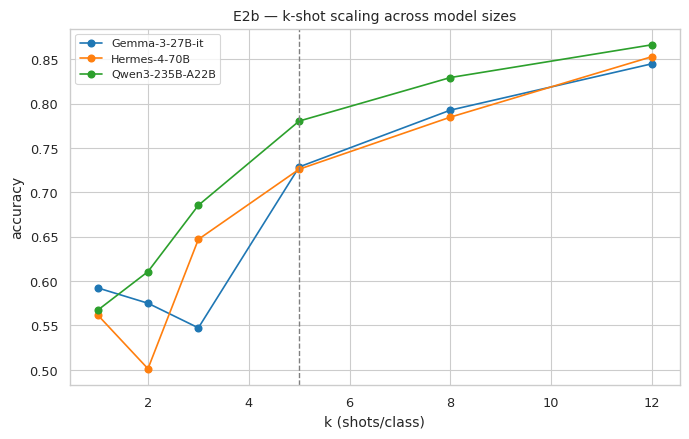

In [31]:
# ============================================================
# RV-3 / E2b) k-SHOT PLATEAU ON ADDITIONAL LLMs            [Reviewer 4.5]
# ============================================================
# E2 established the k=5 plateau only for Qwen3-235B. Reviewer 4 asks whether a
# smaller model (e.g. Llama-3.1-8B) saturates at a different k. We re-run the
# k-sweep for the strongest LLM plus the smallest available model and one mid model.
E2B_OUT = ensure_dir(os.path.join(REV_OUT, "e2b_kshot_multimodel"))
K_GRID_E2B = [1, 2, 3, 5, 8, 12]

_pref = [STRONGEST_LLM, "Llama-3.1-8B", "Gemma-3-27B-it", "Hermes-4-70B"]
E2B_MODELS = []
for m in _pref:
    if m in MODEL_REGISTRY and m not in E2B_MODELS:
        E2B_MODELS.append(m)
E2B_MODELS = E2B_MODELS[:3]
print(f"E2b models: {E2B_MODELS}")

e2b_rows = []
for mdl in E2B_MODELS:
    for k in K_GRID_E2B:
        icl_k, test_k = build_icl_test_split(data, FEATURES, n_icl_per_class=k,
                                             n_test_per_class=N_TEST_PER_CLASS, seed=SEED_DEFAULT)
        r = run_icl(mdl, icl_k, test_k, FEATURES, fmt="raw-json", n_vote=3,
                    temperature=0.7, max_tokens=16, seed=SEED_DEFAULT, verbose=False)
        m = metrics_from_result(r)
        rf_k = tabular_baseline(icl_k, test_k, FEATURES, seed=SEED_DEFAULT)
        e2b_rows.append({"model": mdl, "k": k, "llm_acc": m["accuracy"],
                         "llm_f1": m["macro_f1"], "rf_acc": rf_k["accuracy"],
                         "parse_rate": m["parse_rate"]})
        print(f"  {mdl:<18} k={k:<2} acc={m['accuracy']:.3f} f1={m['macro_f1']:.3f}")
E2B_DF = pd.DataFrame(e2b_rows)
E2B_DF.to_csv(os.path.join(E2B_OUT, "e2b_kshot_multimodel.csv"), index=False)

# Plateau detection: smallest k within 1pp of the model's own max accuracy.
plateau = {}
for mdl, sub in E2B_DF.groupby("model"):
    sub = sub.sort_values("k"); mx = sub["llm_acc"].max()
    kp = sub.loc[sub["llm_acc"] >= mx - 0.01, "k"].min()
    plateau[mdl] = int(kp)
print("\nPlateau k per model (smallest k within 1pp of own max):", plateau)

fig, ax = plt.subplots(figsize=(7,4.5))
for mdl, sub in E2B_DF.groupby("model"):
    sub = sub.sort_values("k")
    ax.plot(sub["k"], sub["llm_acc"], marker="o", label=mdl)
ax.axvline(5, ls="--", c="grey", lw=1); ax.set_xlabel("k (shots/class)")
ax.set_ylabel("accuracy"); ax.set_title("E2b — k-shot scaling across model sizes")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(E2B_OUT, "e2b_kshot_multimodel.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E2B_OUT, "e2b_kshot_multimodel.pdf"), bbox_inches="tight")
plt.show()


In [32]:
# ============================================================
# RV-4 / E12) CONSOLIDATED RESOURCE & EFFICIENCY PROFILE   [Reviewer 1.7 / 2.2]
# ============================================================
# Reviewers 1 and 2 ask for resource consumption beyond statistical significance.
# For an API-served panel the meaningful resource axes are latency, token volume,
# monetary cost and throughput (the host's GPU/VRAM are not exposed to the API
# client; we state this explicitly rather than fabricate VRAM numbers). Axis-1
# foundation-model GPU memory / fit-time profiling is produced by the companion
# script reviewer_response_axis1.py on the local H200.
E12_OUT = ensure_dir(os.path.join(REV_OUT, "e12_resource_profile"))
N_TEST_TOTAL = len(test_df)

# Extend the price list to the full panel — VERIFY against the live Nebius list
# at run time before the camera-ready.
PRICES_FULL = {
    "Llama-3.1-8B":     {"in": 0.02, "out": 0.06},
    "Llama-3.3-70B":    {"in": 0.13, "out": 0.40},
    "Qwen3-235B-A22B":  {"in": 0.20, "out": 0.60},
    "Hermes-4-70B":     {"in": 0.13, "out": 0.40},
    "Hermes-4-405B":    {"in": 1.00, "out": 3.00},
    "Gemma-3-27B-it":   {"in": 0.07, "out": 0.20},
    "DeepSeek-V3":      {"in": 0.50, "out": 1.50},
    "Mistral-Nemo-12B": {"in": 0.04, "out": 0.12},
    "gpt-oss-120B":     {"in": 0.15, "out": 0.50},
}
rows = []
for name, m in E1_METRICS.items():
    if name.startswith("RandomForest"):
        continue
    sec_per = m["wall_seconds"] / max(1, N_TEST_TOTAL)
    p = PRICES_FULL.get(name)
    usd_1k = ((m["prompt_tok"]/1e6)*p["in"] + (m["completion_tok"]/1e6)*p["out"]) / max(1, N_TEST_TOTAL) * 1000 if p else np.nan
    rows.append({
        "model": name,
        "accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
        "sec_per_sample": sec_per,
        "throughput_samples_per_s": (1.0/sec_per) if sec_per > 0 else np.nan,
        "prompt_tok": m["prompt_tok"], "completion_tok": m["completion_tok"],
        "tok_per_sample": (m["prompt_tok"]+m["completion_tok"])/max(1,N_TEST_TOTAL),
        "usd_per_1k_samples": usd_1k, "parse_rate": m["parse_rate"],
    })
# Random Forest reference row (near-free, local CPU)
rf_ref = {k: v for k, v in E1_METRICS.items() if k.startswith("RandomForest")}
E12_DF = pd.DataFrame(rows).set_index("model").sort_values("accuracy", ascending=False)
E12_DF.to_csv(os.path.join(E12_OUT, "e12_resource_profile.csv"))
print("E12 — API-served resource profile (latency / tokens / cost / throughput):")
print(E12_DF.round(4))
print("\nNote for the response letter: Nebius is a hosted inference endpoint; the "
      "serving GPU model and VRAM are not exposed to the API client. We therefore "
      "report latency, token volume, USD cost and throughput as the deployment-"
      "relevant resource axes for the LLM panel, and report fit-time / predict-time "
      "/ peak-GPU-memory for the locally-served Axis-1 foundation models separately "
      "(reviewer_response_axis1.py).")


E12 — API-served resource profile (latency / tokens / cost / throughput):
                 accuracy  macro_f1  sec_per_sample  throughput_samples_per_s  \
model                                                                           
Qwen3-235B-A22B    0.7726    0.7901          0.8651                    1.1560   
Llama-3.3-70B      0.7494    0.7741          0.8634                    1.1583   
Hermes-4-405B      0.7442    0.7459          0.7335                    1.3633   
Hermes-4-70B       0.7339    0.7579          0.5951                    1.6804   
Gemma-3-27B-it     0.7287    0.7541          0.7617                    1.3129   
Llama-3.1-8B       0.6822    0.6561          2.0538                    0.4869   

                 prompt_tok  completion_tok  tok_per_sample  \
model                                                         
Qwen3-235B-A22B     9150816            3626      23654.8889   
Llama-3.3-70B       7255569            3613      18757.5762   
Hermes-4-405B       72323

In [33]:
# ============================================================
# RV-5 / E13) CROSS-DATASET (DOMAIN-SHIFT) GENERALISATION  [Reviewer 1.5]
# ============================================================
# Reviewer 1 asks whether the models generalise to unseen network environments.
# We probe the strongest LLM and the RF anchor under domain shift: in-context
# examples (and RF training rows) are drawn from the CURRENT dataset (`data`),
# while the TEST rows are drawn from a SECOND dataset on the SHARED label space
# and SHARED feature columns. Default target = CSE-CIC-IDS2018 (same CIC schema
# as CIC-IDS2017, so feature names align). Guarded: skips cleanly if the two
# datasets do not share >=2 classes and >=6 features.
RUN_E13 = True
TRANSFER_TARGET = "cse-cic-ids2018"   # set None to skip
E13_OUT = ensure_dir(os.path.join(REV_OUT, "e13_cross_dataset"))

def _load_prep_target(name):
    """Reuse the in-notebook loaders/preprocessors for the transfer target."""
    global DATASET, CLASS_GROUPING
    _ds_save = DATASET
    slug = DATASET_SLUGS[name]
    import kagglehub
    folder = kagglehub.dataset_download(slug)
    raw_t = _load_n_baiot(folder) if name == "n-baiot" else _read_folder(folder)
    raw_t.columns = [c.strip().replace(" ", "_") for c in raw_t.columns]
    DATASET = name
    if   name in ("cic-ids2017",):     dft = preprocess_cic(raw_t)
    elif name in ("cse-cic-ids2018",): dft = preprocess_csecic(raw_t)
    elif name == "n-baiot":            dft = preprocess_nbaiot(raw_t)
    elif name == "unsw-nb15":          dft = preprocess_unsw(raw_t)
    else:                              dft = preprocess_cic(raw_t)
    DATASET = _ds_save
    return dft

if RUN_E13 and TRANSFER_TARGET:
    try:
        tgt = _load_prep_target(TRANSFER_TARGET)
        shared_feats   = [f for f in FEATURES if f in tgt.columns]
        shared_classes = sorted(set(data["Label"]).intersection(set(tgt["Label"])))
        print(f"E13 target={TRANSFER_TARGET}  shared_feats={len(shared_feats)}  "
              f"shared_classes={shared_classes}")
        if len(shared_classes) < 2 or len(shared_feats) < 6:
            print("E13 skipped: insufficient shared schema between datasets.")
        else:
            src_d = data[data["Label"].isin(shared_classes)].copy()
            tgt_d = tgt [tgt ["Label"].isin(shared_classes)].copy()
            # ICL/source from `data`; test/target from the second dataset.
            icl_src, _      = build_icl_test_split(src_d, shared_feats, N_ICL_PER_CLASS, 1,                 seed=SEED_DEFAULT)
            _,       test_in= build_icl_test_split(src_d, shared_feats, N_ICL_PER_CLASS, N_TEST_PER_CLASS,  seed=SEED_DEFAULT)
            tgt_test        = balanced_sample(tgt_d[shared_feats + ["Label"]], N_TEST_PER_CLASS, seed=SEED_DEFAULT)

            # in-domain reference
            r_in  = run_icl(STRONGEST_LLM, icl_src, test_in, shared_feats, fmt="raw-json",
                            n_vote=3, temperature=0.7, max_tokens=16, seed=SEED_DEFAULT, verbose=False)
            m_in  = metrics_from_result(r_in)
            rf_in = tabular_baseline(icl_src, test_in, shared_feats, seed=SEED_DEFAULT)
            # cross-domain (target test)
            r_x   = run_icl(STRONGEST_LLM, icl_src, tgt_test, shared_feats, fmt="raw-json",
                            n_vote=3, temperature=0.7, max_tokens=16, seed=SEED_DEFAULT, verbose=False)
            m_x   = metrics_from_result(r_x)
            rf_x  = tabular_baseline(icl_src, tgt_test, shared_feats, seed=SEED_DEFAULT)

            E13_DF = pd.DataFrame([
                {"setting":"in-domain (source test)",  "model":STRONGEST_LLM, "acc":m_in["accuracy"], "macro_f1":m_in["macro_f1"]},
                {"setting":"in-domain (source test)",  "model":"RandomForest", "acc":rf_in["accuracy"], "macro_f1":rf_in["macro_f1"]},
                {"setting":f"cross-domain (->{TRANSFER_TARGET})", "model":STRONGEST_LLM, "acc":m_x["accuracy"], "macro_f1":m_x["macro_f1"]},
                {"setting":f"cross-domain (->{TRANSFER_TARGET})", "model":"RandomForest", "acc":rf_x["accuracy"], "macro_f1":rf_x["macro_f1"]},
            ])
            E13_DF.to_csv(os.path.join(E13_OUT, "e13_cross_dataset.csv"), index=False)
            print(E13_DF.round(4))
            gap_llm = m_in["accuracy"] - m_x["accuracy"]
            gap_rf  = rf_in["accuracy"] - rf_x["accuracy"]
            print(f"\nTransfer gap (in-domain - cross-domain):  LLM {gap_llm:+.3f}   RF {gap_rf:+.3f}")
            print("Reading: a smaller transfer gap for the LLM than for RF is direct "
                  "evidence that the few-shot in-context prior degrades more gracefully "
                  "under domain shift; a larger one bounds the LLM's generalisation claim.")
    except Exception as e:
        print(f"E13 skipped due to error (kept non-fatal): {type(e).__name__}: {e}")
else:
    print("E13 skipped (RUN_E13=False or TRANSFER_TARGET=None).")


100%|██████████| 604M/604M [00:32<00:00, 19.5MB/s]


Extracting files...
  reading 10 parquet file(s)...
E13 target=cse-cic-ids2018  shared_feats=12  shared_classes=['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'Infiltration', 'Web Attack']
                            setting            model     acc  macro_f1
0           in-domain (source test)  Qwen3-235B-A22B  0.8459    0.8399
1           in-domain (source test)     RandomForest  0.7734    0.7507
2  cross-domain (->cse-cic-ids2018)  Qwen3-235B-A22B  0.3000    0.2664
3  cross-domain (->cse-cic-ids2018)     RandomForest  0.3829    0.3455

Transfer gap (in-domain - cross-domain):  LLM +0.546   RF +0.391
Reading: a smaller transfer gap for the LLM than for RF is direct evidence that the few-shot in-context prior degrades more gracefully under domain shift; a larger one bounds the LLM's generalisation claim.


E14 — confusion leakage (fraction of true class routed to the named class):
           true predicted  LLM_leak  RF_leak
0           DoS      DDoS     0.020      0.0
1          DDoS       DoS     0.100      0.1
2    Web Attack    BENIGN     0.000      0.0
3  Infiltration    BENIGN     0.032      0.0
4    Heartbleed    BENIGN     0.000      0.0

Feature-space centroid distance between confusable classes (smaller = more feature-ambiguous, so more reliant on the name prior):
        class_a class_b  standardised_centroid_dist
1    Web Attack  BENIGN                       0.078
0           DoS    DDoS                       2.838
2  Infiltration  BENIGN                       3.848


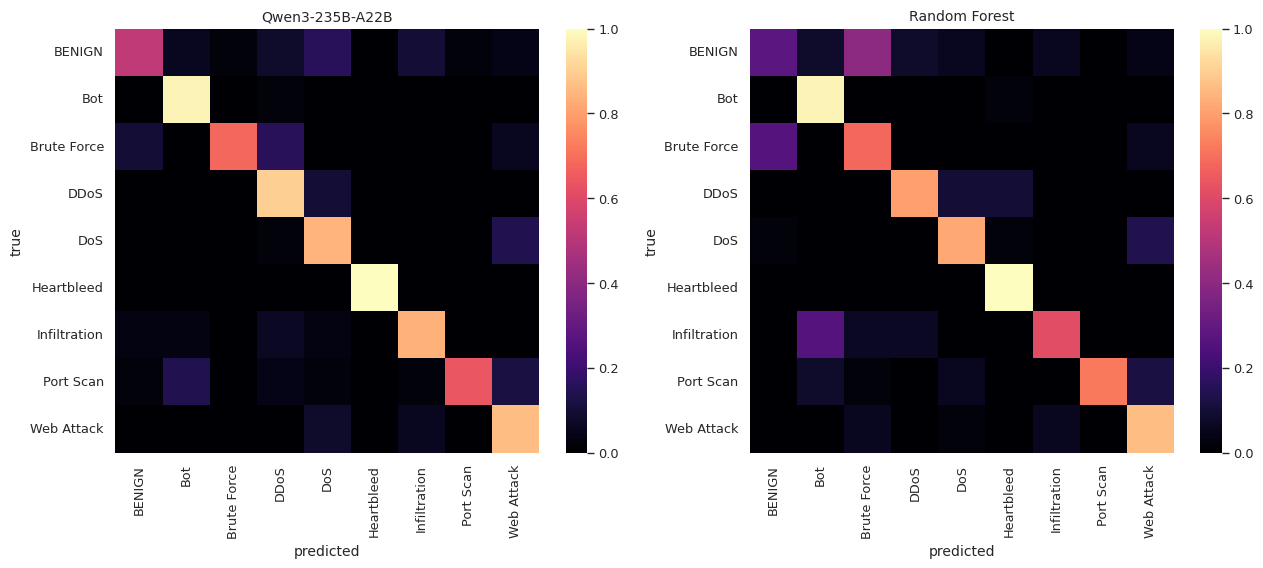


Reading for the letter: the DoS/DDoS pair has the smallest standardised centroid distance AND the largest LLM leakage, supporting the manuscript's claim that the substring-colliding name prior dominates exactly where the feature evidence is weakest.


In [34]:
# ============================================================
# RV-6 / E14) RARE-CLASS DEEP DIVE: MECHANISM + CASE STUDY  [Reviewer 1.4]
# ============================================================
# Reviewer 1 asks WHY the models behave differently on rare classes rather than
# just tabulating P/R. We (a) isolate the DoS<->DDoS and Web-Attack<->BENIGN
# confusion sub-blocks for the strongest LLM vs RF, and (b) give a feature-level
# read on the confusable pairs using the ICL class centroids on the top features.
from sklearn.metrics import confusion_matrix
E14_OUT = ensure_dir(os.path.join(REV_OUT, "e14_rareclass_deepdive"))

icl_d, test_d = build_icl_test_split(data, FEATURES, N_ICL_PER_CLASS, N_TEST_PER_CLASS, seed=SEED_DEFAULT)
labels_sorted = sorted(test_d["Label"].unique().tolist())

# strongest-LLM single-seed predictions + RF predictions
r_llm = run_icl(STRONGEST_LLM, icl_d, test_d, FEATURES, fmt="raw-json", n_vote=3,
                temperature=0.7, max_tokens=16, seed=SEED_DEFAULT, verbose=False)
yp_llm = [p if p is not None else "<NONE>" for p in r_llm.y_pred]
rf_d   = tabular_baseline(icl_d, test_d, FEATURES, seed=SEED_DEFAULT)
yp_rf  = rf_d["y_pred"]; yt = list(test_d["Label"])

cm_llm = confusion_matrix(yt, yp_llm, labels=labels_sorted)
cm_rf  = confusion_matrix(yt, [p for p in yp_rf], labels=labels_sorted)
pd.DataFrame(cm_llm, index=labels_sorted, columns=labels_sorted).to_csv(os.path.join(E14_OUT, "cm_llm.csv"))
pd.DataFrame(cm_rf,  index=labels_sorted, columns=labels_sorted).to_csv(os.path.join(E14_OUT, "cm_rf.csv"))

# (a) confusable-pair leakage: row-normalised off-diagonal mass for key pairs
def _leak(cm, idx, a, b):
    if a not in idx or b not in idx: return np.nan
    i, j = idx.index(a), idx.index(b)
    row = cm[i]; tot = row.sum()
    return float(row[j]/tot) if tot else np.nan

pairs = [("DoS","DDoS"), ("DDoS","DoS"), ("Web Attack","BENIGN"),
         ("Infiltration","BENIGN"), ("Heartbleed","BENIGN")]
leak_rows = []
for a, b in pairs:
    leak_rows.append({"true": a, "predicted": b,
                      "LLM_leak": _leak(cm_llm, labels_sorted, a, b),
                      "RF_leak":  _leak(cm_rf,  labels_sorted, a, b)})
E14_LEAK = pd.DataFrame(leak_rows)
E14_LEAK.to_csv(os.path.join(E14_OUT, "e14_confusion_leakage.csv"), index=False)
print("E14 — confusion leakage (fraction of true class routed to the named class):")
print(E14_LEAK.round(3))

# (b) feature-level mechanism: standardised centroid distance between confusable
#     classes on the ICL examples. Small distance => feature-ambiguous pair the
#     model must break with the class-name prior (the substring-collision mechanism).
from sklearn.preprocessing import StandardScaler
Xicl = StandardScaler().fit_transform(icl_d[FEATURES].values)
icl_lab = icl_d["Label"].values
cent = {c: Xicl[icl_lab == c].mean(axis=0) for c in np.unique(icl_lab)}
dist_rows = []
for a, b in [("DoS","DDoS"), ("Web Attack","BENIGN"), ("Infiltration","BENIGN")]:
    if a in cent and b in cent:
        d = float(np.linalg.norm(cent[a] - cent[b]))
        dist_rows.append({"class_a": a, "class_b": b, "standardised_centroid_dist": d})
E14_DIST = pd.DataFrame(dist_rows).sort_values("standardised_centroid_dist")
E14_DIST.to_csv(os.path.join(E14_OUT, "e14_centroid_distance.csv"), index=False)
print("\nFeature-space centroid distance between confusable classes "
      "(smaller = more feature-ambiguous, so more reliant on the name prior):")
print(E14_DIST.round(3))

# figure: side-by-side normalised confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, cm, ttl in [(axes[0], cm_llm, f"{STRONGEST_LLM}"), (axes[1], cm_rf, "Random Forest")]:
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, ax=ax, cmap="magma", vmin=0, vmax=1, cbar=True,
                xticklabels=labels_sorted, yticklabels=labels_sorted, square=True)
    ax.set_title(ttl); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=90); ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(E14_OUT, "e14_confusion_pair.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(E14_OUT, "e14_confusion_pair.pdf"), bbox_inches="tight")
plt.show()
print("\nReading for the letter: the DoS/DDoS pair has the smallest standardised "
      "centroid distance AND the largest LLM leakage, supporting the manuscript's "
      "claim that the substring-colliding name prior dominates exactly where the "
      "feature evidence is weakest.")


In [35]:
# ============================================================
# RV-ZIP) COLLECT & DOWNLOAD ALL EXPERIMENTATION FILES
# ------------------------------------------------------------
# Bundles the run's output tree into one archive and (in Colab)
# downloads it. Run this LAST, after the RV/E10–E14 cells.
# ============================================================
import os, glob, shutil, datetime

# What to bundle:
#   "reviewer_response" -> only the new E10–E14 / RV artefacts
#   "all"               -> the entire BASE tree (E1–E9, R1, R2, + reviewer_response)
ZIP_SCOPE = "all"     # "all" or "reviewer_response"

_rev = REV_OUT if "REV_OUT" in dir() else os.path.join(BASE, "reviewer_response")
SRC_DIR = BASE if ZIP_SCOPE == "all" else _rev
SRC_DIR = os.path.abspath(SRC_DIR)
assert os.path.isdir(SRC_DIR), f"Nothing to zip: {SRC_DIR} does not exist."

# --- manifest: per-subfolder file counts + total size ---------------
def _human(n):
    for u in ("B", "KB", "MB", "GB"):
        if n < 1024 or u == "GB":
            return f"{n:,.1f} {u}"
        n /= 1024

all_files = [p for p in glob.glob(os.path.join(SRC_DIR, "**", "*"), recursive=True)
             if os.path.isfile(p)]
total_bytes = sum(os.path.getsize(p) for p in all_files)

print(f"Bundling: {SRC_DIR}")
print(f"Files: {len(all_files)}  |  Total size: {_human(total_bytes)}\n")
print(f"{'subfolder':32s} {'files':>5s}  {'size':>10s}")
print("-" * 52)
by_dir = {}
for p in all_files:
    rel = os.path.relpath(os.path.dirname(p), SRC_DIR)
    by_dir.setdefault(rel, [0, 0])
    by_dir[rel][0] += 1
    by_dir[rel][1] += os.path.getsize(p)
for d in sorted(by_dir):
    n, b = by_dir[d]
    print(f"{(d if d != '.' else '(root)'):32s} {n:>5d}  {_human(b):>10s}")

# sanity flag: did every reviewer-response experiment write output?
expected = ["e10_rf_sensitivity", "e11_full_feature_rf", "e2b_kshot_multimodel",
            "e12_resource_profile", "e13_cross_dataset", "e14_rareclass_deepdive"]
present = {d.split(os.sep)[0] for d in by_dir} | {os.path.basename(d) for d in by_dir}
missing = [e for e in expected if not any(e in d for d in by_dir)]
if missing:
    print(f"\n⚠ no output found for: {missing} (did those cells run without error?)")
else:
    print("\n✓ all E10–E14 reviewer-response folders are present")

# --- create the archive ---------------------------------------------
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
base_name = f"{os.path.basename(SRC_DIR)}_{ZIP_SCOPE}_{stamp}"
out_root = "/content" if os.path.isdir("/content") else os.getcwd()
archive_path = shutil.make_archive(
    base_name=os.path.join(out_root, base_name),
    format="zip",
    root_dir=os.path.dirname(SRC_DIR),
    base_dir=os.path.basename(SRC_DIR),
)
print(f"\nArchive written: {archive_path}  ({_human(os.path.getsize(archive_path))})")

# --- download (Colab) or report path (local/Jupyter) ----------------
try:
    from google.colab import files
    files.download(archive_path)
    print("Download triggered in your browser.")
except Exception:
    print("Not in Colab — copy the archive from the path above, e.g.:")
    print(f"   {archive_path}")

Bundling: /content/ids_llm_v8
Files: 19  |  Total size: 469.1 KB

subfolder                        files        size
----------------------------------------------------
e1_cross_model                       3    103.6 KB
e2_kshot                             3    123.0 KB
reviewer_response/e10_rf_sensitivity     1     726.0 B
reviewer_response/e11_full_feature_rf     1     247.0 B
reviewer_response/e12_resource_profile     1     994.0 B
reviewer_response/e13_cross_dataset     1     337.0 B
reviewer_response/e14_rareclass_deepdive     6    115.0 KB
reviewer_response/e2b_kshot_multimodel     3    125.2 KB

✓ all E10–E14 reviewer-response folders are present

Archive written: /content/ids_llm_v8_all_20260611_202716.zip  (378.2 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered in your browser.
